# Pengujian Skenario: 7 Model x 10 Dataset (Prequential Test-Then-Train + Deteksi Drift)

Protokol sesuai skenario pengujian kelompok:

1. **Chunk 1 = warm-up**: melatih model awal, akurasi belum dihitung. Satu chunk = **500 baris**.
2. **Chunk 2 dst**: *test dulu, baru latih* (interleaved test-then-train).
3. **Deteksi drift**: skor CUSUM-style θ atas error-rate chunk vs jendela referensi; alarm bila θ ≥ 3,0.
4. **Dua strategi adaptasi** per model: `continuous` (tanpa reset) dan `reset` (model dibangun ulang saat alarm).
5. **Metrik**: akurasi rata-rata, prequential kappa, jumlah alarm, RT, PDE, FTDE, latensi per chunk.

**7 model** (satu dataset dicoba bergantian oleh ketujuhnya):

| # | Model | Implementasi |
|---|---|---|
| 1 | DT | Hoeffding Tree (river) |
| 2 | HAT | Hoeffding Adaptive Tree (river) |
| 3 | ARF | Adaptive Random Forest, 10 pohon (river) |
| 4 | SVM | linear SGD hinge loss (scikit-learn) |
| 5 | ANN | MLP 1 hidden layer 32 neuron (scikit-learn) |
| 6 | BELS | implementasi ringkas: ensemble lapisan output di atas pemetaan acak bersama, mini-chunk |
| 7 | DACD | implementasi ringkas: window CUSUM internal + pemilihan sampel + retrain MLP |

**Dataset simulasi** (file hasil generate MOA oleh kelompok, di `Dataset Real Word/datasets_synthetic`, 100.000 baris per dataset):

| Dataset | Fitur | Kelas | Drift |
|---|---|---|---|
| sea | 3 | 2 | gradual (ganti fungsi klasifikasi) |
| rbfblips | 20 | 4 | abrupt (beda centroid) |
| led_abrupt | 24 | 10 | abrupt di 50% (permutasi label) |
| led_gradual | 24 | 10 | gradual di 25/50/75% |
| tree | 30 | 10 | abrupt (beda struktur pohon) |
| hyperplane | 10 | 2 | incremental (mag_change) |

**Dataset real-world**: electricity (45.312), kddcup99 (494.020), covertype (581.012), weather BASEL (3.654).

Perkiraan durasi Run All penuh dengan 14 worker: **1-1,5 jam** (dataset terberat menentukan; KDD/Covertype masing-masing sekitar 20-30 menit). Bila ingin lebih cepat lagi: kecilkan `STRATEGIES` jadi satu, turunkan `ARF_TREES`, atau turunkan `SIM_SAMPLES`.

**Tahan mati listrik**: setiap chunk di-checkpoint otomatis ke `hasil_pengujian/checkpoint/`. Jalankan ulang Run All setelah gangguan, dan proses berlanjut dari chunk terakhir yang belum selesai; run yang sudah selesai dilewati. Hapus folder `hasil_pengujian` bila ingin mulai dari nol.

Cara pakai: **Run All**. Sel pertama otomatis menginstal dependensi bila kernel belum memilikinya.

In [ ]:
import importlib.util
import subprocess
import sys

NEED = {
    "river": "river",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
}
missing = [pip_name for mod, pip_name in NEED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Menginstal paket yang kurang:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    print("Selesai. Lanjut ke sel berikutnya.")
else:
    print("Semua dependensi tersedia di:", sys.executable)

Semua dependensi tersedia di: c:\python314\python.exe


In [ ]:
import json
import os
import time
import warnings
from pathlib import Path

import cloudpickle
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from river import forest, metrics, tree
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA = Path("dataset")
OUT = Path("hasil_pengujian")
OUT.mkdir(exist_ok=True)
CKPT_DIR = OUT / "checkpoint"
CKPT_DIR.mkdir(exist_ok=True)

THETA_SEVERE = 3.0
RECOVERY_RATIO = 0.95
SEED = 42
ARF_TREES = 10
STRATEGIES = ("continuous", "reset")

# dataset simulasi: file hasil generate MOA oleh kelompok (100.000 baris per dataset)
SIM_DIR = Path("Dataset Real Word") / "datasets_synthetic"

# penyesuaian otomatis kemampuan device: sisakan thread untuk sistem/navigasi
RESERVE_THREADS = 2
TOTAL_THREADS = os.cpu_count() or 2
N_WORKERS = max(1, TOTAL_THREADS - RESERVE_THREADS)
WORKERS_HEAVY = min(N_WORKERS, max(4, N_WORKERS - 4))
LOG_DIR = OUT / "logs"
LOG_DIR.mkdir(exist_ok=True)

print(f"CPU terdeteksi: {TOTAL_THREADS} thread | worker: {N_WORKERS} ({RESERVE_THREADS} disisakan)")
print(f"Dataset berat (kddcup99, covertype) pakai maksimal {WORKERS_HEAVY} worker agar RAM aman")
print("Konfigurasi siap. Output:", OUT.resolve(), "| checkpoint:", CKPT_DIR.resolve())

CPU terdeteksi: 16 thread | worker: 14 (2 disisakan)
Dataset berat (kddcup99, covertype) pakai maksimal 10 worker agar RAM aman
Konfigurasi siap. Output: C:\Users\adamf\Documents\Kuliah\ITS\Semester 1\Kecerdasan Komputasional\Tugas Besar\hasil_pengujian | checkpoint: C:\Users\adamf\Documents\Kuliah\ITS\Semester 1\Kecerdasan Komputasional\Tugas Besar\hasil_pengujian\checkpoint


## 1. Pemuat dataset

- **Dataset simulasi (6)** dibaca dari file CSV hasil generate MOA oleh kelompok, di folder `Dataset Real Word/datasets_synthetic` (Sea, RBFBlips, LED_abrupt, LED_gradual, Tree, Hyperplane; masing-masing 100.000 baris, format `feature_0..N,target`, kelas di kolom terakhir). Drift sudah tertanam di dalam data sesuai pengaturan MOA saat generate.
- **Dataset real-world (4)** dibaca dari folder `dataset/` (electricity, kddcup99, covertype, weather).
- Catatan penamaan: folder `Dataset Real Word` itu sebenarnya berisi dataset **simulasi**; dataset real-world justru ada di folder `dataset`. Cukup diketahui saja, path di notebook mengikuti nama folder yang ada.

In [ ]:
def _load_moa(name, desc):
    df = pd.read_csv(SIM_DIR / f"{name}.csv")
    y = df["target"].astype(str)
    X = df.drop(columns=["target"])
    return X, y, 500, desc


def load_sea():
    return _load_moa("Sea", "SEA (MOA): gradual drift 25/50/75%, 100.000 baris, 3 fitur, 2 kelas")


def load_rbfblips():
    return _load_moa("RBFBlips", "RBFBlips (MOA): abrupt drift 25/50/75%, 100.000 baris, 20 fitur, 4 kelas")


def load_led_abrupt():
    return _load_moa("LED_abrupt", "LED_abrupt (MOA): abrupt drift di 50%, 100.000 baris, 24 fitur, 10 kelas")


def load_led_gradual():
    return _load_moa("LED_gradual", "LED_gradual (MOA): gradual drift 25/50/75%, 100.000 baris, 24 fitur, 10 kelas")


def load_tree():
    return _load_moa("Tree", "Tree (MOA): abrupt drift 25/50/75%, 100.000 baris, 30 fitur, 10 kelas")


def load_hyperplane():
    return _load_moa("Hyperplane", "Hyperplane (MOA): incremental drift t=0.001, 100.000 baris, 10 fitur, 2 kelas")


def load_electricity():
    df = pd.read_csv(DATA / "electricity" / "electricity.csv")
    y = df["class"]
    X = df.drop(columns=["date", "class"])
    return X, y, 500, "Elec2: 45.312 sampel, 7 fitur, 2 kelas (UP/DOWN)"


def load_covertype():
    df = pd.read_csv(DATA / "covertype" / "covtype.data", header=None)
    y = df.iloc[:, -1].astype(str)
    X = df.iloc[:, :-1]
    return X, y, 500, "Covertype: 581.012 sampel, 54 fitur, 7 kelas"


def load_kddcup99():
    df = pd.read_csv(DATA / "kddcup99" / "kdd_df.csv")
    y = df["target"]
    X = df.drop(columns=["target", "attack_type"])
    X = pd.get_dummies(X, columns=["protocol_type", "service", "flag"])
    # shortcut: kosong kategori dibangun dari seluruh file (ruang kategori, bukan label)
    return X, y, 500, "KDD Cup 1999 (10%): 494.020 sampel, 41 fitur (+one-hot), 23 kelas"


def load_weather():
    w = pd.read_csv(DATA / "weather" / "weather_prediction_dataset_light.csv")
    p = pd.read_csv(DATA / "weather" / "weather_prediction_picnic_labels.csv")
    cols = ["DATE"] + [c for c in w.columns if c.startswith("BASEL_") and not c.endswith("_wind_speed")]
    X = w[cols].merge(p[["DATE", "BASEL_picnic_weather"]], on="DATE")
    y = X["BASEL_picnic_weather"].map({True: "yes", False: "no"})
    X = X.drop(columns=["DATE", "BASEL_picnic_weather"])
    return X, y, 500, "Weather BASEL: 3.654 sampel, 9 fitur, 2 kelas (picnic yes/no); 8 chunk"


LOADERS = {
    "sea": load_sea,
    "rbfblips": load_rbfblips,
    "led_abrupt": load_led_abrupt,
    "led_gradual": load_led_gradual,
    "tree": load_tree,
    "hyperplane": load_hyperplane,
    "electricity": load_electricity,
    "weather": load_weather,
    "kddcup99": load_kddcup99,
    "covertype": load_covertype,
}
print("Loader siap:", ", ".join(LOADERS))

Loader siap: sea, rbfblips, led_abrupt, led_gradual, tree, hyperplane, electricity, weather, kddcup99, covertype


### Kapan drift terjadi di tiap dataset

Ingat: satu chunk = 500 baris, dan dataset simulasi berisi 100.000 baris = 200 chunk (chunk 1 = warm-up). Posisi drift 25% / 50% / 75% berarti perubahan konsep masuk pada **sampel ke-25.000 / 50.000 / 75.000**, yaitu **chunk ke-51, 101, dan 151**.

| Dataset | Jenis drift | Kapan berubah | Apa yang berubah |
|---|---|---|---|
| Sea | gradual | chunk 51, 101, 151 | fungsi klasifikasi berganti (ambang pada fitur berubah), transisi bertahap |
| RBFBlips | abrupt | chunk 51, 101, 151 | centroid klaster penghasil data diganti total, distribusi berubah mendadak |
| LED_abrupt | abrupt | chunk 101 saja | konfigurasi segmen LED yang rusak berubah, fitur relevan bergeser, sekali di tengah |
| LED_gradual | gradual | chunk 51, 101, 151 | sama seperti LED_abrupt tetapi perubahannya bertahap di tiga titik |
| Tree | abrupt | chunk 51, 101, 151 | struktur pohon acak penghasil label diganti pohon baru |
| Hyperplane | incremental | terus-menerus | batas hyperplane bergeser sedikit pada tiap sampel (t = 0.001), tidak ada titik tunggal |
| Electricity, Kddcup99, Covertype, Weather | real-world | tidak dikendalikan | drift alami bila ada; posisinya tidak diketahui sehingga dideteksi dari lonjakan error-rate |

Cara memakai tabel ini saat membaca hasil:
1. Di dataset simulasi, akurasi model seharusnya **anjlok di sekitar chunk 51 / 101 / 151** — itu efek drift.
2. Detektor CUSUM idealnya membunyikan alarm (tanda x merah) tak lama setelah titik tersebut. Alarm yang jauh sebelum/sesudahnya berarti terlalu sensitif / terlambat.
3. **Recovery time** dihitung dari chunk alarm sampai akurasi kembali ke minimal 95% baseline. Pada drift 75% (chunk 151), sisa stream hanya 50 chunk — pemulihan bisa gagal sebelum stream habis, dan itu memang bagian yang diuji.
4. Kalau akurasi tidak anjlok sama sekali di titik drift, model tersebut kebal terhadap drift itu (driftnya terlalu halus untuknya) — misalnya drift Sea yang hanya menggeser ambang.

## 2. Komponen: standardisasi online dan detektor drift

- `OnlineScaler`: standardisasi hanya dari data yang sudah dipakai latihan (mencegah *data leakage*).
- `WindowCUSUM`: skor θ gaya window CUSUM atas error-rate chunk relatif terhadap referensi; dipakai detektor luar (strategi) dan internal DACD.

In [ ]:
class OnlineScaler:
    """Standardisasi hanya dari data yang sudah dipakai latihan (hindari leakage)."""

    def __init__(self):
        self.n = 0
        self.mean = None
        self.m2 = None

    def transform(self, X):
        arr = np.asarray(X, dtype=float)
        if self.mean is None:
            return arr
        return (arr - self.mean) / np.sqrt(self.var + 1e-9)

    def update(self, X):
        arr = np.asarray(X, dtype=float)
        if self.mean is None:
            self.mean = np.zeros(arr.shape[1])
            self.m2 = np.zeros(arr.shape[1])
        for row in arr:
            self.n += 1
            delta = row - self.mean
            self.mean += delta / self.n
            self.m2 += delta * (row - self.mean)

    @property
    def var(self):
        return self.m2 / max(self.n, 1)


class WindowCUSUM:
    """Skor gaya window CUSUM atas error-rate chunk relatif terhadap referensi."""

    def __init__(self, k=0.10, lambd=0.99, threshold=THETA_SEVERE):
        self.k = k
        self.lambd = lambd
        self.threshold = threshold
        self.s = 0.0
        self.ref_error = None
        self.ref_n = 0

    def update_ref(self, error):
        if self.ref_error is None:
            self.ref_error = error
            self.ref_n = 1
        else:
            self.ref_error = (self.ref_error * self.ref_n + error) / (self.ref_n + 1)
            self.ref_n = min(self.ref_n + 1, 30)

    def score(self, error):
        if self.ref_error is None or self.ref_error <= 0:
            self.update_ref(error)
            return 0.0
        excess = (error - self.ref_error) / self.ref_error - self.k
        self.s = max(0.0, self.lambd * self.s + excess)
        return self.s

    def alarm(self, theta):
        return theta >= self.threshold


print("OnlineScaler dan WindowCUSUM siap.")

OnlineScaler dan WindowCUSUM siap.


## 3. Tujuh model

Antarmuka seragam: `test_chunk(X, y)`, `train_chunk(X, y)`, `reset(seed)`.

- **DT / HAT / ARF**: model river, test-then-train per sampel di dalam chunk.
- **SVM / ANN**: scikit-learn dengan `partial_fit`/`fit` per chunk.
- **BELS (ringkas)**: pemetaan acak bersama (tanh) + ensemble lapisan output ridge; anggota terlemah dibuang (passive ensemble, mini-chunk) mengikuti ide paper BELS.
- **DACD (ringkas)**: MLP + CUSUM internal; saat alarm, model dilatih ulang atas buffer + chunk dengan oversampling kelas minoritas, mengikuti ide paper DACD.

In [ ]:
class RiverModel:
    """HT/HAT/ARF: test-then-train per sampel di dalam chunk. spec disimpan agar bisa di-pickle."""

    def __init__(self, name, spec, seed):
        self.name = name
        self.spec = spec
        self.seed = seed
        self.model = self._build()

    def _build(self):
        if self.spec == "ht":
            return tree.HoeffdingTreeClassifier(grace_period=100, delta=1e-4)
        if self.spec == "hat":
            return tree.HoeffdingAdaptiveTreeClassifier(seed=self.seed, grace_period=100, delta=1e-4)
        return forest.ARFClassifier(n_models=ARF_TREES, seed=self.seed)

    def test_chunk(self, X, y):
        hits = 0
        preds = []
        for xi, yi in zip(X.to_dict("records"), y):
            p = self.model.predict_one(xi)
            preds.append(p)
            hits += p == yi
        return np.array(preds), hits / len(y)

    def train_chunk(self, X, y):
        for xi, yi in zip(X.to_dict("records"), y):
            self.model.learn_one(xi, yi)

    def reset(self, seed):
        self.model = self._build()


class SklearnModel:
    def __init__(self, seed, kind):
        self.seed = seed
        self.kind = kind
        self.scaler = OnlineScaler()
        self.classes = None
        self.buffer = {}
        self.fitted_classes = None
        self.model = self._new()

    def _new(self):
        if self.kind == "svm":
            return SGDClassifier(loss="hinge", alpha=1e-4, random_state=self.seed)
        return MLPClassifier(hidden_layer_sizes=(32,), random_state=self.seed, max_iter=1, warm_start=True)

    def test_chunk(self, X, y):
        Xs = self.scaler.transform(X)
        preds = self.model.predict(Xs)
        return preds, float(np.mean(np.asarray(y).astype(str) == preds.astype(str)))

    def _fit_incremental(self, X, y_arr):
        known = self.fitted_classes or sorted(set(y_arr))
        missing = [c for c in known if c not in set(y_arr)]
        if missing:
            pad = pd.DataFrame([self.buffer[c] for c in missing if c in self.buffer], columns=X.columns)
            keep = [c for c in missing if c in self.buffer]
            if len(pad):
                X = pd.concat([X, pad], ignore_index=True)
                y_arr = np.concatenate([y_arr, np.array(keep)])
        Xs = self.scaler.transform(X)
        try:
            self.model.fit(Xs, y_arr)
        except ValueError:
            self.model = self._new()
            self.model.fit(Xs, y_arr)
        self.fitted_classes = sorted(set(y_arr))

    def train_chunk(self, X, y):
        y_arr = np.asarray(y).astype(str)
        if self.kind == "svm":
            Xs = self.scaler.transform(X)
            self.model.partial_fit(Xs, y_arr, classes=self.classes)
        else:
            for c in np.unique(y_arr):
                self.buffer[c] = X.loc[y_arr == c].iloc[-1]
            self._fit_incremental(X, y_arr)
        self.scaler.update(X)

    def reset(self, seed):
        self.scaler = OnlineScaler()
        self.buffer = {}
        self.fitted_classes = None
        self.model = self._new()


class BELSModel:
    """BELS ringkas: ensemble lapisan output ridge di atas pemetaan acak bersama."""

    name = "BELS"

    def __init__(self, seed, n_z=60, n_h=40, ridge=1.0, max_members=8, keep=4):
        self.seed = seed
        self.n_z, self.n_h, self.ridge = n_z, n_h, ridge
        self.max_members, self.keep = max_members, keep
        self.scaler = OnlineScaler()
        self.classes = None
        self.rng = np.random.default_rng(seed)
        self.Wz = self.bz = self.Wh = self.bh = None
        self.members = []

    def _init_map(self, d):
        self.Wz = self.rng.normal(0, 0.5, (d, self.n_z))
        self.bz = self.rng.normal(0, 0.1, self.n_z)
        self.Wh = self.rng.normal(0, 0.5, (self.n_z, self.n_h))
        self.bh = self.rng.normal(0, 0.1, self.n_h)

    def _map(self, Xs):
        Z = np.tanh(Xs @ self.Wz + self.bz)
        H = np.tanh(Z @ self.Wh + self.bh)
        return np.hstack([Z, H])

    def test_chunk(self, X, y):
        if not self.members:
            preds = np.array([str(self.classes[0])] * len(y), dtype=object)
            return preds, float(np.mean(np.asarray(y).astype(str) == preds))
        A = self._map(self.scaler.transform(X))
        scores = np.mean([A @ beta for beta, _ in self.members], axis=0)
        preds = np.asarray(self.classes, dtype=object)[scores.argmax(axis=1)]
        return preds, float(np.mean(np.asarray(y).astype(str) == preds))

    def train_chunk(self, X, y):
        y_arr = np.asarray(y).astype(str)
        Xs = self.scaler.transform(X)
        if self.Wz is None:
            self._init_map(Xs.shape[1])
        A = self._map(Xs)
        Y = (y_arr[:, None] == np.asarray(self.classes)[None, :]).astype(float)
        target = Y.argmax(axis=1)
        accs = []
        for beta, ema in self.members:
            acc = float(np.mean((A @ beta).argmax(axis=1) == target))
            accs.append(0.7 * ema + 0.3 * acc)
        G = A.T @ A + self.ridge * np.eye(A.shape[1])
        beta_new = np.linalg.solve(G, A.T @ Y)
        acc_new = float(np.mean((A @ beta_new).argmax(axis=1) == target))
        self.members = [(b, a) for (b, _), a in zip(self.members, accs)] + [(beta_new, acc_new)]
        if len(self.members) > self.max_members:
            self.members = sorted(self.members, key=lambda m: m[1], reverse=True)[: self.keep]
        self.scaler.update(X)

    def reset(self, seed):
        self.rng = np.random.default_rng(seed)
        self.Wz = self.bz = self.Wh = self.bh = None
        self.members = []
        self.scaler = OnlineScaler()


class DACDModel:
    """DACD ringkas: window CUSUM internal + pemilihan sampel (buffer, oversampling) + retrain MLP."""

    name = "DACD"

    def __init__(self, seed, hidden=32, buffer_size=2000):
        self.seed = seed
        self.hidden = hidden
        self.buffer_size = buffer_size
        self.scaler = OnlineScaler()
        self.classes = None
        self.fitted_classes = None
        self.buffer = []
        self.cusum = WindowCUSUM()
        self.model = MLPClassifier(hidden_layer_sizes=(hidden,), random_state=seed, max_iter=1, warm_start=True)

    def test_chunk(self, X, y):
        Xs = self.scaler.transform(X)
        preds = self.model.predict(Xs)
        return preds, float(np.mean(np.asarray(y).astype(str) == preds.astype(str)))

    def _fit(self, Xs, y_arr, fresh=False, max_iter=1):
        if fresh:
            self.model = MLPClassifier(hidden_layer_sizes=(self.hidden,), random_state=self.seed, max_iter=max_iter)
        try:
            self.model.fit(Xs, y_arr)
        except ValueError:
            self.model = MLPClassifier(hidden_layer_sizes=(self.hidden,), random_state=self.seed, max_iter=max_iter)
            self.model.fit(Xs, y_arr)
        self.fitted_classes = sorted(set(y_arr))

    def train_chunk(self, X, y):
        y_arr = np.asarray(y).astype(str)
        for i in range(len(y_arr)):
            self.buffer.append((X.iloc[i].to_numpy(dtype=float), y_arr[i]))
        if len(self.buffer) > self.buffer_size:
            del self.buffer[: len(self.buffer) - self.buffer_size]
        Xs = self.scaler.transform(X)
        fitted = True
        try:
            err = 1.0 - float(np.mean(self.model.predict(Xs) == y_arr))
        except ValueError:
            fitted = False
            err = None
        theta = self.cusum.score(err) if fitted else 0.0
        if fitted and self.cusum.alarm(theta):
            buf_X = np.array([b[0] for b in self.buffer])
            buf_y = np.array([b[1] for b in self.buffer])
            counts = {c: int(np.sum(buf_y == c)) for c in np.unique(buf_y)}
            med = int(np.median(list(counts.values())))
            extra = []
            for c, cnt in counts.items():
                if cnt < med:
                    idxs = np.where(buf_y == c)[0]
                    take = self.seed + len(extra)
                    extra.extend(np.random.default_rng(take).choice(idxs, med - cnt, replace=True).tolist())
            if extra:
                buf_X = np.vstack([buf_X, buf_X[extra]])
                buf_y = np.concatenate([buf_y, buf_y[extra]])
            self._fit(self.scaler.transform(buf_X), buf_y, fresh=True, max_iter=3)
            self.cusum = WindowCUSUM()
        else:
            if fitted:
                self.cusum.update_ref(err)
            known = self.fitted_classes or sorted(set(y_arr))
            missing = [c for c in known if c not in set(y_arr)]
            if missing:
                pad = [b[0] for b in self.buffer[::-1] if b[1] in missing][: len(missing)]
                pad_y = [b[1] for b in self.buffer[::-1] if b[1] in missing][: len(missing)]
                if pad:
                    Xs = np.vstack([Xs, self.scaler.transform(np.array(pad))])
                    y_arr = np.concatenate([y_arr, np.array(pad_y)])
            self._fit(Xs, y_arr)
        self.scaler.update(X)

    def reset(self, seed):
        self.scaler = OnlineScaler()
        self.buffer = []
        self.cusum = WindowCUSUM()
        self.fitted_classes = None
        self.model = MLPClassifier(hidden_layer_sizes=(self.hidden,), random_state=seed, max_iter=1, warm_start=True)


def make_models(seed):
    svm = SklearnModel(seed, "svm")
    svm.name = "SVM"
    ann = SklearnModel(seed, "ann")
    ann.name = "ANN"
    return [
        RiverModel("DT", "ht", seed),
        RiverModel("HAT", "hat", seed),
        RiverModel("ARF", "arf", seed),
        svm,
        ann,
        BELSModel(seed),
        DACDModel(seed),
    ]


print("7 model siap: DT, HAT, ARF, SVM, ANN, BELS, DACD.")

7 model siap: DT, HAT, ARF, SVM, ANN, BELS, DACD.


## 4. Fungsi pengujian (paralel + resume)

Satu run = satu model × satu strategi. Ke-14 run per dataset dijalankan **paralel di proses terpisah** memakai joblib.

**Penyesuaian device otomatis**: jumlah worker = jumlah thread CPU dikurangi `RESERVE_THREADS` (default 2, disisakan untuk sistem/navigasi). Contoh: Ryzen 9 5980HS 8 core/16 thread → 14 worker. Dataset berat (kddcup99, covertype) dibatasi `WORKERS_HEAVY` agar RAM tidak jebol. Setiap worker membatasi BLAS 1 thread (threadpoolctl) supaya tidak oversubscription. Ubah `RESERVE_THREADS`/`N_WORKERS` di sel konfigurasi bila perlu.

**Mekanisme resume** (kalau mati listrik / kernel mati / Run All dihentikan):
- Setiap selesai satu chunk, state run disimpan sebagai checkpoint atomik di `hasil_pengujian/checkpoint/` (model, kappa, CUSUM, riwayat chunk).
- Saat dijalankan ulang, run yang sudah selesai dilewati (`[selesai sebelumnya]`), run yang setengah jalan dilanjutkan dari chunk terakhir (`[lanjut]`), dan checkpoint yang rusak diulang dari awal run itu.
- Resume valid karena semua dataset deterministik: seluruh dataset (simulasi MOA maupun real-world) dibaca dari file yang sama.
- Log per run juga tersimpan di `hasil_pengujian/logs/<dataset>_<model>_<strategi>.log` agar progres tetap bisa dipantau saat paralel.
- Bila muncul `[peringatan] checkpoint ... gagal ditulis`, berarti file checkpoint sedang dikunci proses lain (kernel lama yang masih jalan, antivirus, atau OneDrive). Pastikan hanya satu kernel menjalankan notebook ini: **Interrupt lalu Restart kernel** sebelum Run All ulang.
- Untuk memulai semua dari nol: hapus folder `hasil_pengujian`.

In [ ]:
def _atomic_replace(src, dst, tries=6):
    """os.replace tahan kunci file (kernel lain/antivirus/OneDrive): retry, lalu fallback, terakhir menyerah tanpa crash."""
    for i in range(tries):
        try:
            os.replace(src, dst)
            return True
        except PermissionError:
            time.sleep(0.25 * (i + 1))
    try:
        if dst.exists():
            dst.unlink()
    except PermissionError:
        pass
    try:
        os.replace(src, dst)
        return True
    except PermissionError:
        print(f"    [peringatan] checkpoint chunk ini gagal ditulis (file terkunci): {dst.name}")
        try:
            src.unlink()
        except OSError:
            pass
        return False


def _log(tag, msg):
    """Cetak ke layar dan simpan ke file log per run (agar progres tetap terlihat saat paralel)."""
    print(msg, flush=True)
    try:
        with open(LOG_DIR / f"{tag}.log", "a", encoding="utf-8") as f:
            f.write(msg + "\n")
    except OSError:
        pass


def run_one(model, X, y, chunk, strategy, seed, classes, tag, log_every=10):
    csv_path = OUT / f"{tag}_chunks.csv"
    sum_path = OUT / f"{tag}_summary.json"
    ckpt_path = CKPT_DIR / f"{tag}.pkl"

    if csv_path.exists() and sum_path.exists() and not ckpt_path.exists():
        df = pd.read_csv(csv_path)
        with open(sum_path, encoding="utf-8") as f:
            summary = json.load(f)
        _log(tag, f"    [selesai sebelumnya] {tag}: avg_acc={summary['avg_acc']:.4f}")
        return df, summary

    kappa = metrics.CohenKappa()
    cusum = WindowCUSUM()
    rows = []
    alarms = []
    chunk_id = 0
    if ckpt_path.exists():
        try:
            with open(ckpt_path, "rb") as f:
                state = cloudpickle.load(f)
            model, kappa, cusum = state["model"], state["kappa"], state["cusum"]
            rows, alarms, chunk_id = state["rows"], state["alarms"], state["chunk_id"]
            _log(tag, f"    [lanjut] {tag} dari chunk {chunk_id + 1}")
        except Exception:
            rows, alarms, chunk_id = [], [], 0
            _log(tag, f"    [checkpoint rusak, run diulang dari awal] {tag}")

    if hasattr(model, "classes"):
        model.classes = classes
    n = len(y)
    total_chunks = (n + chunk - 1) // chunk
    start = chunk_id * chunk
    while start < n:
        end = min(start + chunk, n)
        Xc, yc = X.iloc[start:end], y.iloc[start:end]
        chunk_id += 1
        t0 = time.perf_counter()
        if chunk_id == 1:
            model.train_chunk(Xc, yc)
            rows.append({"chunk": chunk_id, "n": end - start, "acc": np.nan, "kappa": np.nan,
                         "theta": 0.0, "alarm": False, "latency_ms": (time.perf_counter() - t0) * 1000})
        else:
            preds, acc = model.test_chunk(Xc, yc)
            for yi, pi in zip(yc, preds):
                kappa.update(str(yi), str(pi))
            error = 1.0 - acc
            theta = cusum.score(error)
            alarm = cusum.alarm(theta)
            if alarm:
                alarms.append(chunk_id)
            if strategy == "reset" and alarm:
                model.reset(seed)
                cusum = WindowCUSUM()
            else:
                cusum.update_ref(error)
            model.train_chunk(Xc, yc)
            rows.append({"chunk": chunk_id, "n": end - start, "acc": acc, "kappa": kappa.get(),
                         "theta": theta, "alarm": alarm, "latency_ms": (time.perf_counter() - t0) * 1000})
        if chunk_id % log_every == 0 or chunk_id == total_chunks:
            r = rows[-1]
            acc_txt = "warm-up" if np.isnan(r["acc"]) else f"{r['acc']:.3f}"
            _log(tag, f"    [{model.name} / {strategy}] chunk {chunk_id:>4}/{total_chunks} acc={acc_txt} theta={r['theta']:.2f}")
        tmp_path = ckpt_path.with_suffix(".tmp")
        with open(tmp_path, "wb") as f:
            cloudpickle.dump({"model": model, "kappa": kappa, "cusum": cusum, "rows": rows,
                              "alarms": alarms, "chunk_id": chunk_id}, f)
        _atomic_replace(tmp_path, ckpt_path)
        start = end
    df = pd.DataFrame(rows)

    accs = df["acc"].dropna()
    baseline_idx = df[(df["chunk"] > 1) & (~df["alarm"])].head(max(3, int(len(df) * 0.1) + 1))
    baseline = float(baseline_idx["acc"].mean()) if len(baseline_idx) else float(accs.iloc[0])
    threshold = RECOVERY_RATIO * baseline
    eval_df = df.dropna(subset=["acc"]).copy()
    eval_df["degraded"] = eval_df["acc"] < threshold

    episodes = int((eval_df["degraded"] & ~eval_df["degraded"].shift(1, fill_value=False)).sum())
    ftde = float(eval_df["degraded"].mean())
    pde = episodes / max(len(eval_df), 1)
    rt = None
    for a in alarms:
        after = eval_df[eval_df["chunk"] > a]
        ok = after[~after["degraded"]]
        if len(ok):
            rt = int(ok["chunk"].iloc[0] - a)
            break
    summary = {
        "model": model.name, "strategy": strategy, "chunks": len(df),
        "avg_acc": float(accs.mean()),
        "final_kappa": float(df["kappa"].dropna().iloc[-1]) if len(df["kappa"].dropna()) else np.nan,
        "baseline": baseline, "threshold": threshold, "alarms": len(alarms),
        "pde": pde, "ftde": ftde, "rt_chunks": rt if rt is not None else -1,
        "avg_latency_ms": float(df["latency_ms"].mean()),
    }
    df.to_csv(csv_path, index=False)
    with open(sum_path, "w", encoding="utf-8") as f:
        json.dump(summary, f)
    if ckpt_path.exists():
        ckpt_path.unlink()
    return df, summary


def plot_curves(name, curves):
    models = sorted({label.split(" / ")[0] for label in curves})
    ncols = 2
    nrows = (len(models) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.2 * nrows), sharex=True, sharey=True, squeeze=False)
    cmap = matplotlib.colormaps["tab10"]
    for i, model in enumerate(models):
        ax = axes[i // ncols][i % ncols]
        color = cmap(i % 10)
        for strategy, ls in (("continuous", "-"), ("reset", "--")):
            df = curves.get(f"{model} / {strategy}")
            if df is None:
                continue
            d = df.dropna(subset=["acc"])
            ax.plot(d["chunk"], d["acc"], marker="o", markersize=2.5, linewidth=1.3,
                    linestyle=ls, color=color, label=strategy)
            alarms = d[d["alarm"]]
            if len(alarms):
                ax.scatter(alarms["chunk"], alarms["acc"], marker="x", s=24, color="red", linewidths=1.1, zorder=5)
        ax.set_title(model, fontsize=10)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="lower right")
    for j in range(len(models), nrows * ncols):
        axes[j // ncols][j % ncols].set_visible(False)
    fig.suptitle(f"Prequential: {name} — garis penuh = continuous, putus-putus = reset, x merah = alarm drift", fontsize=11)
    fig.supxlabel("Chunk")
    fig.supylabel("Akurasi real-time")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(OUT / f"plot_{name}.png", dpi=150)
    plt.show()
    return fig


ALL_SUMMARIES = []
MODEL_NAMES = None


def _run_task(name, model_index, strategy):
    """Satu tugas paralel = satu run (model x strategi) pada satu dataset; jalan di proses terpisah."""
    X, y, chunk, desc = LOADERS[name]()
    classes = np.array(sorted(y.astype(str).unique()))
    model = make_models(SEED)[model_index]
    tag = f"{name}_{model.name}_{strategy}".replace(" ", "")
    _log(tag, f"=== {name} | {desc} | chunk={chunk} | baris={len(y)} | mulai {model.name}/{strategy}")
    try:
        from threadpoolctl import threadpool_limits
        limits = threadpool_limits(1)
    except ImportError:
        from contextlib import nullcontext
        limits = nullcontext()
    with limits:
        df, summary = run_one(model, X, y, chunk, strategy, SEED, classes, tag)
    return summary


def run_dataset(name):
    global MODEL_NAMES
    if MODEL_NAMES is None:
        MODEL_NAMES = [m.name for m in make_models(SEED)]
    tasks = [(i, s) for i in range(len(MODEL_NAMES)) for s in STRATEGIES]
    if name in ("kddcup99", "covertype"):
        n_jobs = min(WORKERS_HEAVY, len(tasks))
    else:
        n_jobs = min(N_WORKERS, len(tasks))
    print(f"=== {name} | {len(tasks)} run paralel | {n_jobs} worker "
          f"(CPU {TOTAL_THREADS} thread, {RESERVE_THREADS} disisakan) ===", flush=True)
    results = Parallel(n_jobs=n_jobs, verbose=1)(delayed(_run_task)(name, i, s) for i, s in tasks)
    curves = {}
    rows = []
    for summary in results:
        tag = f"{name}_{summary['model']}_{summary['strategy']}".replace(" ", "")
        curves[f"{summary['model']} / {summary['strategy']}"] = pd.read_csv(OUT / f"{tag}_chunks.csv")
        ALL_SUMMARIES.append({"dataset": name, **summary})
        rows.append(summary)
        print(f"  >> {summary['model']:<5} {summary['strategy']:<10} avg_acc={summary['avg_acc']:.4f} "
              f"kappa={summary['final_kappa']:.4f} alarm={summary['alarms']} RT={summary['rt_chunks']} "
              f"PDE={summary['pde']:.3f} FTDE={summary['ftde']:.3f} lat={summary['avg_latency_ms']:.1f}ms", flush=True)
    plot_curves(name, curves)
    return pd.DataFrame(rows).set_index(["model", "strategy"])


print("Fungsi pengujian siap (paralel + resume).")

Fungsi pengujian siap (paralel + resume).


## SEA — gradual drift 25/50/75% (drift di chunk 51, 101, 151)

=== sea | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:   16.8s remaining:  1.7min
[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:   17.0s finished


  >> DT    continuous avg_acc=0.8439 kappa=0.6642 alarm=25 RT=4 PDE=0.075 FTDE=0.291 lat=54.3ms
  >> DT    reset      avg_acc=0.8614 kappa=0.7026 alarm=2 RT=1 PDE=0.050 FTDE=0.126 lat=53.2ms
  >> HAT   continuous avg_acc=0.8653 kappa=0.7095 alarm=11 RT=1 PDE=0.040 FTDE=0.070 lat=124.4ms
  >> HAT   reset      avg_acc=0.8665 kappa=0.7126 alarm=1 RT=1 PDE=0.040 FTDE=0.070 lat=122.5ms
  >> ARF   continuous avg_acc=0.8807 kappa=0.7438 alarm=0 RT=-1 PDE=0.015 FTDE=0.045 lat=901.3ms
  >> ARF   reset      avg_acc=0.8807 kappa=0.7438 alarm=0 RT=-1 PDE=0.015 FTDE=0.045 lat=900.1ms
  >> SVM   continuous avg_acc=0.8172 kappa=0.6103 alarm=0 RT=-1 PDE=0.050 FTDE=0.050 lat=16.8ms
  >> SVM   reset      avg_acc=0.8172 kappa=0.6103 alarm=0 RT=-1 PDE=0.050 FTDE=0.050 lat=16.5ms
  >> ANN   continuous avg_acc=0.8361 kappa=0.6522 alarm=17 RT=1 PDE=0.005 FTDE=0.040 lat=23.9ms
  >> ANN   reset      avg_acc=0.8165 kappa=0.6189 alarm=1 RT=8 PDE=0.010 FTDE=0.075 lat=24.4ms
  >> BELS  continuous avg_acc=0.8632 ka

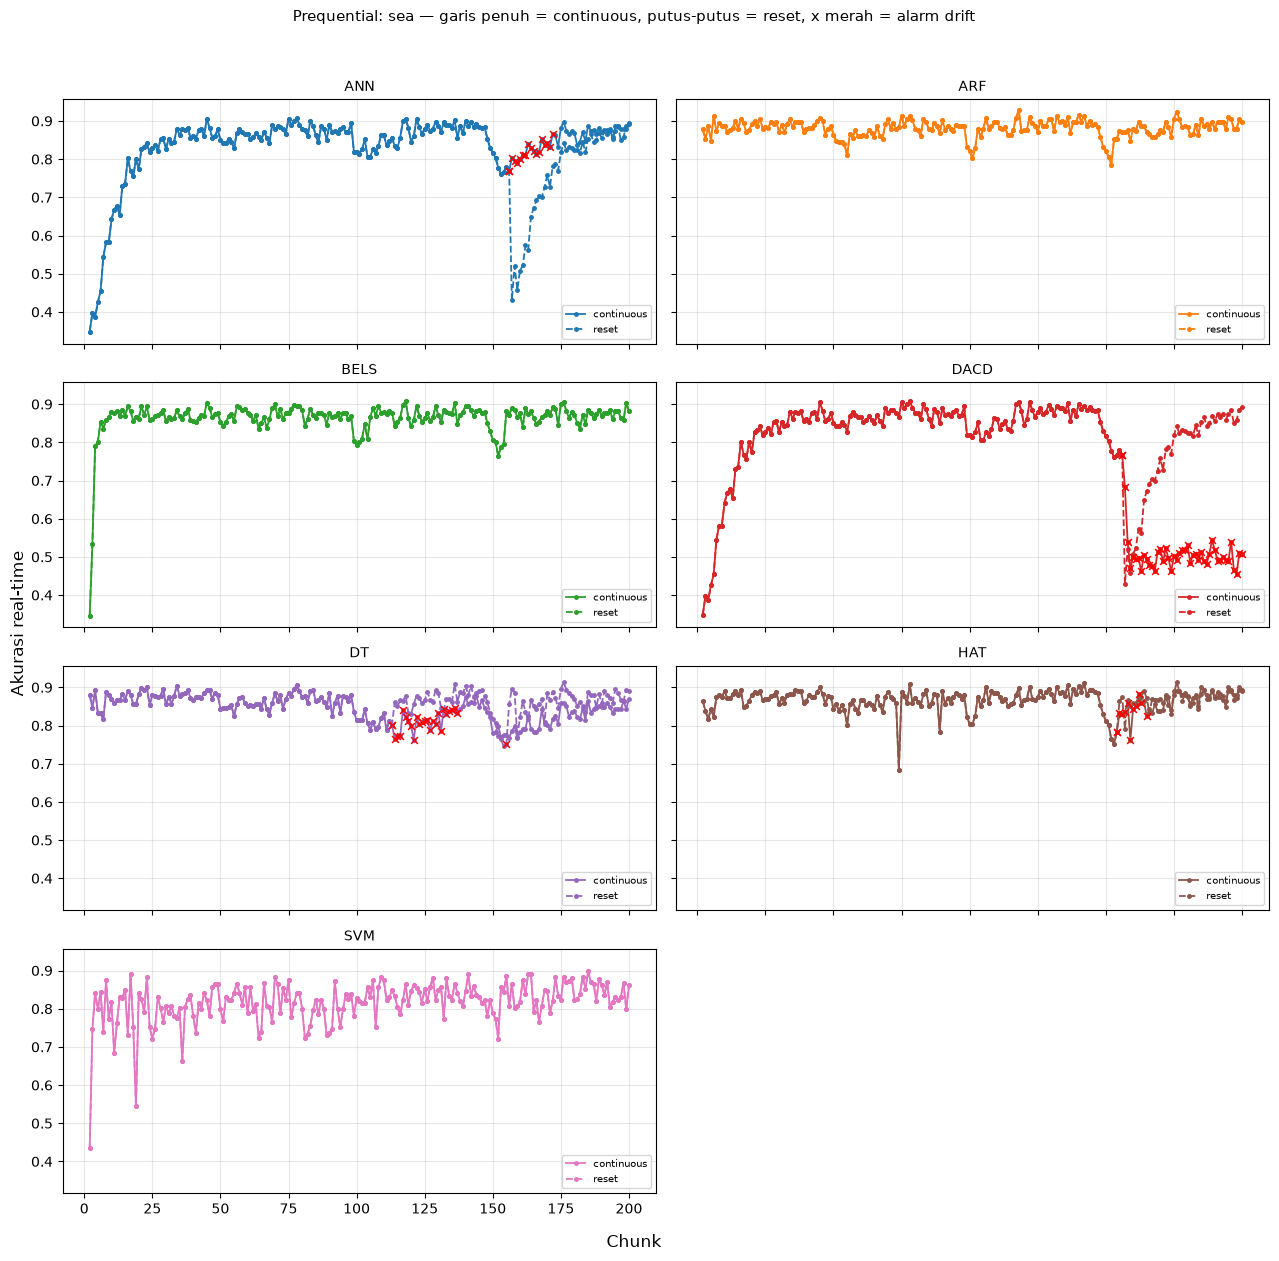

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.843859     0.664242  0.868476   0.825052      25   
      reset          200  0.861447     0.702629  0.868476   0.825052       2   
HAT   continuous     200  0.865307     0.709537  0.867143   0.823786      11   
      reset          200  0.866462     0.712574  0.867143   0.823786       1   
ARF   continuous     200  0.880734     0.743846  0.883429   0.839257       0   
      reset          200  0.880734     0.743846  0.883429   0.839257       0   
SVM   continuous     200  0.817196     0.610303  0.771619   0.733038       0   
      reset          200  0.817196     0.610303  0.771619   0.733038       0   
ANN   continuous     200  0.836060     0.652212  0.637429   0.605557      17   
      reset          200  0.816482     0.618872  0.637429   0.605557       1   
BELS  continuous     200  0.863226     0.708738  0.822667   0.781533       0   
      reset          200  0.863226     0.708738  0.822667   0.781533       0   
DACD  continuous     200  0.758462     0.516125  0.637429   0.605557      45   
      reset          200  0.816482     0.618872  0.637429   0.605557       1   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.075377  0.291457          4       54.348804  
      reset       0.050251  0.125628          1       53.215837  
HAT   continuous  0.040201  0.070352          1      124.449950  
      reset       0.040201  0.070352          1      122.539409  
ARF   continuous  0.015075  0.045226         -1      901.254887  
      reset       0.015075  0.045226         -1      900.136356  
SVM   continuous  0.050251  0.050251         -1       16.824937  
      reset       0.050251  0.050251         -1       16.512156  
ANN   continuous  0.005025  0.040201          1       23.886396  
      reset       0.010050  0.075377          8       24.447253  
BELS  continuous  0.010050  0.015075         -1       20.088892  
      reset       0.010050  0.015075         -1       19.770357  
DACD  continuous  0.010050  0.256281          1       54.458798  
      reset       0.010050  0.075377          8       53.780597

In [ ]:
run_dataset("sea")

## RBFBlips — abrupt drift 25/50/75% (drift di chunk 51, 101, 151)

=== rbfblips | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    1.5s remaining:    9.3s


  >> DT    continuous avg_acc=0.9180 kappa=0.8868 alarm=175 RT=1 PDE=0.075 FTDE=0.226 lat=198.4ms
  >> DT    reset      avg_acc=0.9590 kappa=0.9435 alarm=15 RT=1 PDE=0.065 FTDE=0.070 lat=208.9ms
  >> HAT   continuous avg_acc=0.9518 kappa=0.9335 alarm=154 RT=8 PDE=0.055 FTDE=0.126 lat=310.4ms
  >> HAT   reset      avg_acc=0.9569 kappa=0.9406 alarm=17 RT=1 PDE=0.070 FTDE=0.070 lat=296.0ms
  >> ARF   continuous avg_acc=0.9777 kappa=0.9693 alarm=147 RT=1 PDE=0.015 FTDE=0.015 lat=947.9ms
  >> ARF   reset      avg_acc=0.9766 kappa=0.9678 alarm=3 RT=1 PDE=0.015 FTDE=0.015 lat=971.8ms
  >> SVM   continuous avg_acc=0.9797 kappa=0.9720 alarm=150 RT=1 PDE=0.015 FTDE=0.015 lat=26.1ms
  >> SVM   reset      avg_acc=0.9801 kappa=0.9726 alarm=3 RT=1 PDE=0.015 FTDE=0.015 lat=26.1ms
  >> ANN   continuous avg_acc=0.7588 kappa=0.6688 alarm=99 RT=1 PDE=0.020 FTDE=0.181 lat=31.8ms
  >> ANN   reset      avg_acc=0.7462 kappa=0.6606 alarm=2 RT=10 PDE=0.020 FTDE=0.196 lat=33.0ms
  >> BELS  continuous avg_acc=0.

[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    1.9s finished


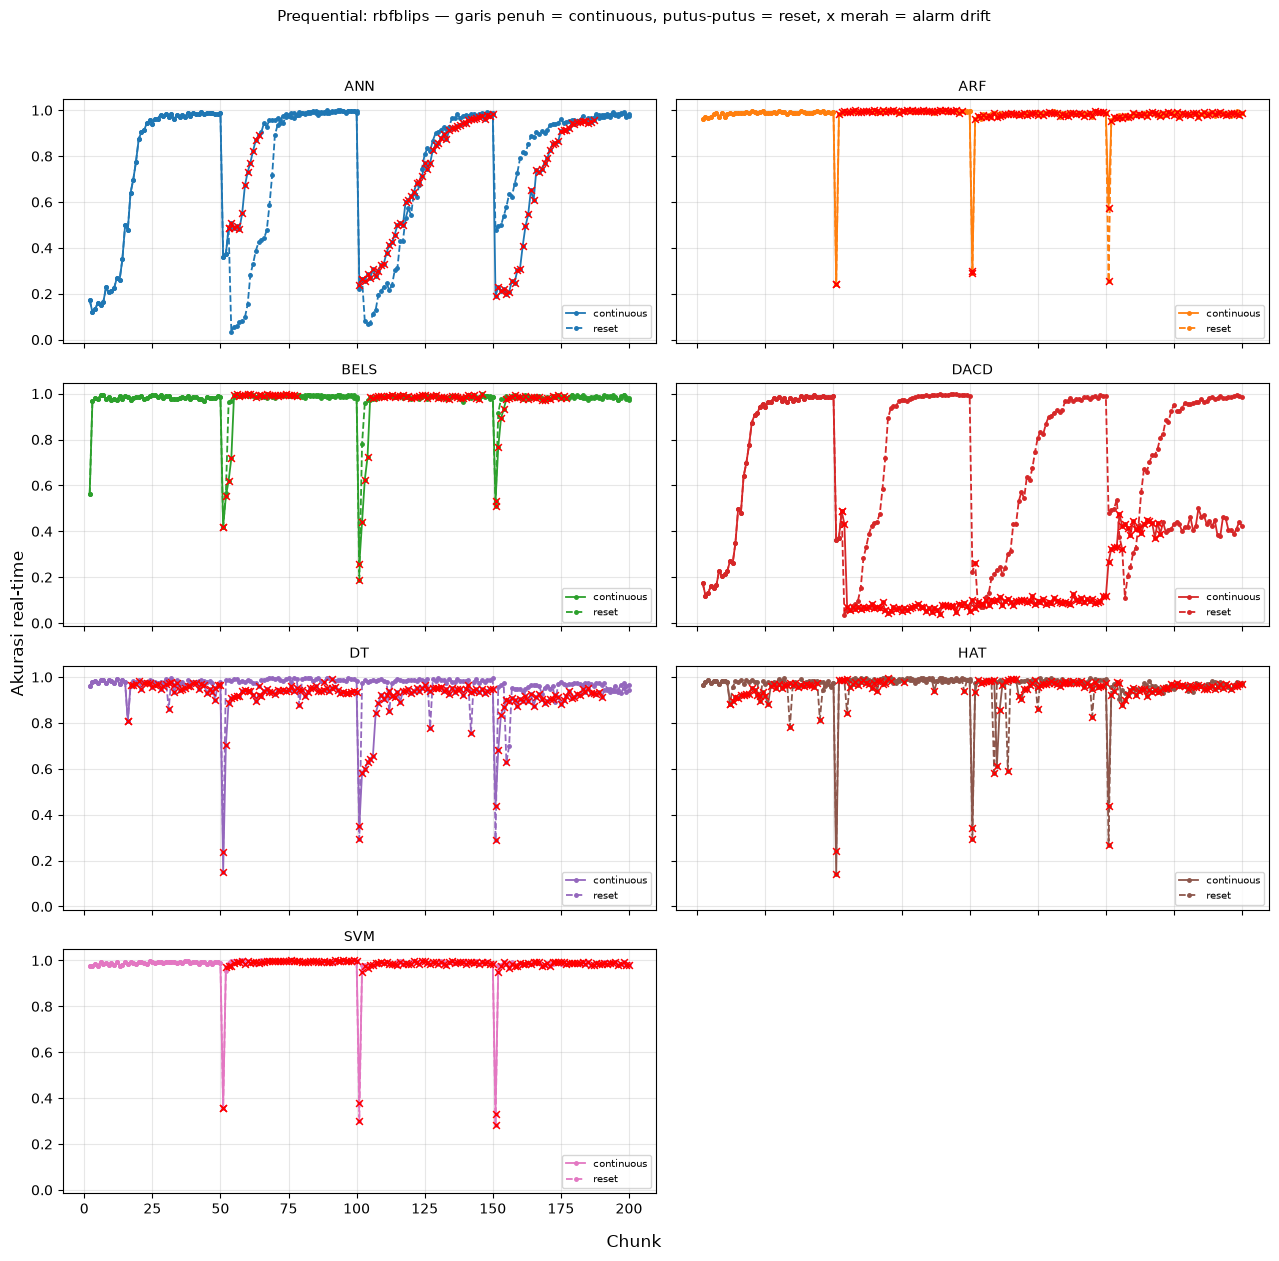

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.918000     0.886761  0.965429   0.917157     175   
      reset          200  0.958965     0.943452  0.978952   0.930005      15   
HAT   continuous     200  0.951769     0.933499  0.976667   0.927833     154   
      reset          200  0.956905     0.940589  0.979143   0.930186      17   
ARF   continuous     200  0.977749     0.969346  0.982571   0.933443     147   
      reset          200  0.976593     0.967760  0.982571   0.933443       3   
SVM   continuous     200  0.979698     0.972030  0.985619   0.936338     150   
      reset          200  0.980121     0.972624  0.985619   0.936338       3   
ANN   continuous     200  0.758784     0.668759  0.402095   0.381990      99   
      reset          200  0.746191     0.660645  0.402095   0.381990       2   
BELS  continuous     200  0.962422     0.948304  0.961238   0.913176     101   
      reset          200  0.969538     0.958106  0.961238   0.913176       3   
DACD  continuous     200  0.332322     0.157499  0.402095   0.381990     118   
      reset          200  0.720352     0.626708  0.402095   0.381990       3   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.075377  0.226131          1      198.427594  
      reset       0.065327  0.070352          1      208.936346  
HAT   continuous  0.055276  0.125628          8      310.352081  
      reset       0.070352  0.070352          1      295.955961  
ARF   continuous  0.015075  0.015075          1      947.935704  
      reset       0.015075  0.015075          1      971.768543  
SVM   continuous  0.015075  0.015075          1       26.104347  
      reset       0.015075  0.015075          1       26.115257  
ANN   continuous  0.020101  0.180905          1       31.773624  
      reset       0.020101  0.195980         10       33.020397  
BELS  continuous  0.020101  0.060302          4       22.795402  
      reset       0.020101  0.030151          2       22.900346  
DACD  continuous  0.025126  0.587940          1       84.607304  
      reset       0.025126  0.231156         10       79.968300

In [ ]:
run_dataset("rbfblips")

## LED abrupt — drift tepat di 50% (chunk 101)

=== led_abrupt | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    0.7s remaining:    4.6s


  >> DT    continuous avg_acc=0.5699 kappa=0.5220 alarm=98 RT=12 PDE=0.035 FTDE=0.593 lat=405.8ms
  >> DT    reset      avg_acc=0.7101 kappa=0.6779 alarm=5 RT=1 PDE=0.050 FTDE=0.080 lat=432.0ms
  >> HAT   continuous avg_acc=0.6406 kappa=0.6006 alarm=58 RT=5 PDE=0.065 FTDE=0.412 lat=692.3ms
  >> HAT   reset      avg_acc=0.6995 kappa=0.6661 alarm=6 RT=2 PDE=0.060 FTDE=0.131 lat=632.9ms
  >> ARF   continuous avg_acc=0.7154 kappa=0.6837 alarm=3 RT=2 PDE=0.015 FTDE=0.045 lat=2041.0ms
  >> ARF   reset      avg_acc=0.7107 kappa=0.6786 alarm=1 RT=1 PDE=0.035 FTDE=0.085 lat=2086.4ms
  >> SVM   continuous avg_acc=0.6848 kappa=0.6498 alarm=0 RT=-1 PDE=0.035 FTDE=0.055 lat=31.5ms
  >> SVM   reset      avg_acc=0.6848 kappa=0.6498 alarm=0 RT=-1 PDE=0.035 FTDE=0.055 lat=31.2ms
  >> ANN   continuous avg_acc=0.4683 kappa=0.4092 alarm=65 RT=24 PDE=0.020 FTDE=0.206 lat=45.0ms
  >> ANN   reset      avg_acc=0.5028 kappa=0.4476 alarm=1 RT=15 PDE=0.010 FTDE=0.151 lat=46.5ms
  >> BELS  continuous avg_acc=0.66

[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    1.1s finished


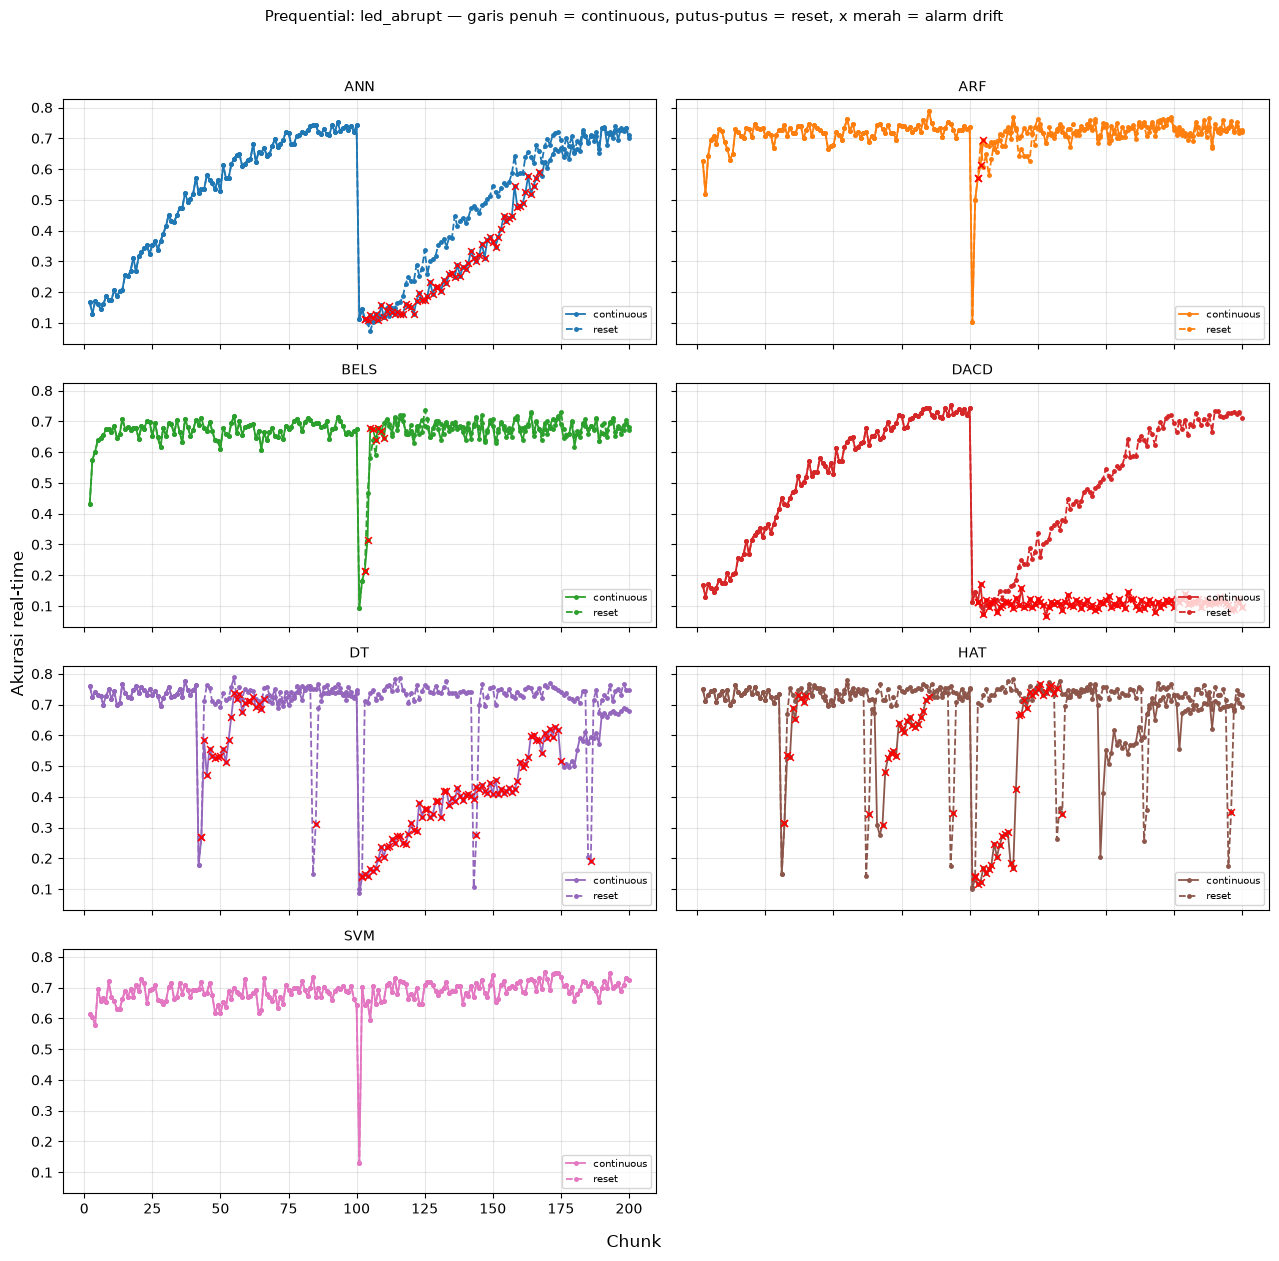

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.569859     0.522046  0.734667   0.697933      98   
      reset          200  0.710070     0.677850  0.734667   0.697933       5   
HAT   continuous     200  0.640553     0.600619  0.735143   0.698386      58   
      reset          200  0.699528     0.666129  0.735143   0.698386       6   
ARF   continuous     200  0.715367     0.683747  0.689238   0.654776       3   
      reset          200  0.710714     0.678577  0.689238   0.654776       1   
SVM   continuous     200  0.684804     0.649778  0.666571   0.633243       0   
      reset          200  0.684804     0.649778  0.666571   0.633243       0   
ANN   continuous     200  0.468251     0.409191  0.220095   0.209090      65   
      reset          200  0.502814     0.447587  0.220095   0.209090       1   
BELS  continuous     200  0.663668     0.626334  0.650095   0.617590       8   
      reset          200  0.666050     0.628985  0.650095   0.617590       1   
DACD  continuous     200  0.316905     0.240966  0.220095   0.209090      98   
      reset          200  0.502814     0.447587  0.220095   0.209090       1   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.035176  0.592965         12      405.811082  
      reset       0.050251  0.080402          1      432.026167  
HAT   continuous  0.065327  0.412060          5      692.258218  
      reset       0.060302  0.130653          2      632.888471  
ARF   continuous  0.015075  0.045226          2     2041.001588  
      reset       0.035176  0.085427          1     2086.442240  
SVM   continuous  0.035176  0.055276         -1       31.531605  
      reset       0.035176  0.055276         -1       31.218178  
ANN   continuous  0.020101  0.206030         24       45.016044  
      reset       0.010050  0.150754         15       46.467651  
BELS  continuous  0.025126  0.050251          2       22.965679  
      reset       0.030151  0.060302          3       23.498336  
DACD  continuous  0.010050  0.567839         -1       87.883433  
      reset       0.010050  0.150754         15       84.213796

In [ ]:
run_dataset("led_abrupt")

## LED gradual — drift 25/50/75% (chunk 51, 101, 151)

=== led_gradual | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    0.7s remaining:    4.5s


  >> DT    continuous avg_acc=0.5568 kappa=0.5076 alarm=105 RT=34 PDE=0.030 FTDE=0.724 lat=428.4ms
  >> DT    reset      avg_acc=0.6820 kappa=0.6466 alarm=5 RT=1 PDE=0.065 FTDE=0.211 lat=471.1ms
  >> HAT   continuous avg_acc=0.6422 kappa=0.6025 alarm=58 RT=5 PDE=0.065 FTDE=0.307 lat=689.3ms
  >> HAT   reset      avg_acc=0.6857 kappa=0.6508 alarm=6 RT=2 PDE=0.060 FTDE=0.226 lat=675.4ms
  >> ARF   continuous avg_acc=0.6859 kappa=0.6510 alarm=14 RT=2 PDE=0.040 FTDE=0.151 lat=2366.6ms
  >> ARF   reset      avg_acc=0.6842 kappa=0.6492 alarm=3 RT=4 PDE=0.040 FTDE=0.186 lat=2331.7ms
  >> SVM   continuous avg_acc=0.6585 kappa=0.6205 alarm=4 RT=3 PDE=0.035 FTDE=0.171 lat=33.7ms
  >> SVM   reset      avg_acc=0.6533 kappa=0.6148 alarm=1 RT=5 PDE=0.050 FTDE=0.201 lat=33.9ms
  >> ANN   continuous avg_acc=0.4231 kappa=0.3591 alarm=11 RT=1 PDE=0.010 FTDE=0.141 lat=48.1ms
  >> ANN   reset      avg_acc=0.3721 kappa=0.3024 alarm=1 RT=16 PDE=0.020 FTDE=0.221 lat=48.4ms
  >> BELS  continuous avg_acc=0.641

[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    1.0s finished


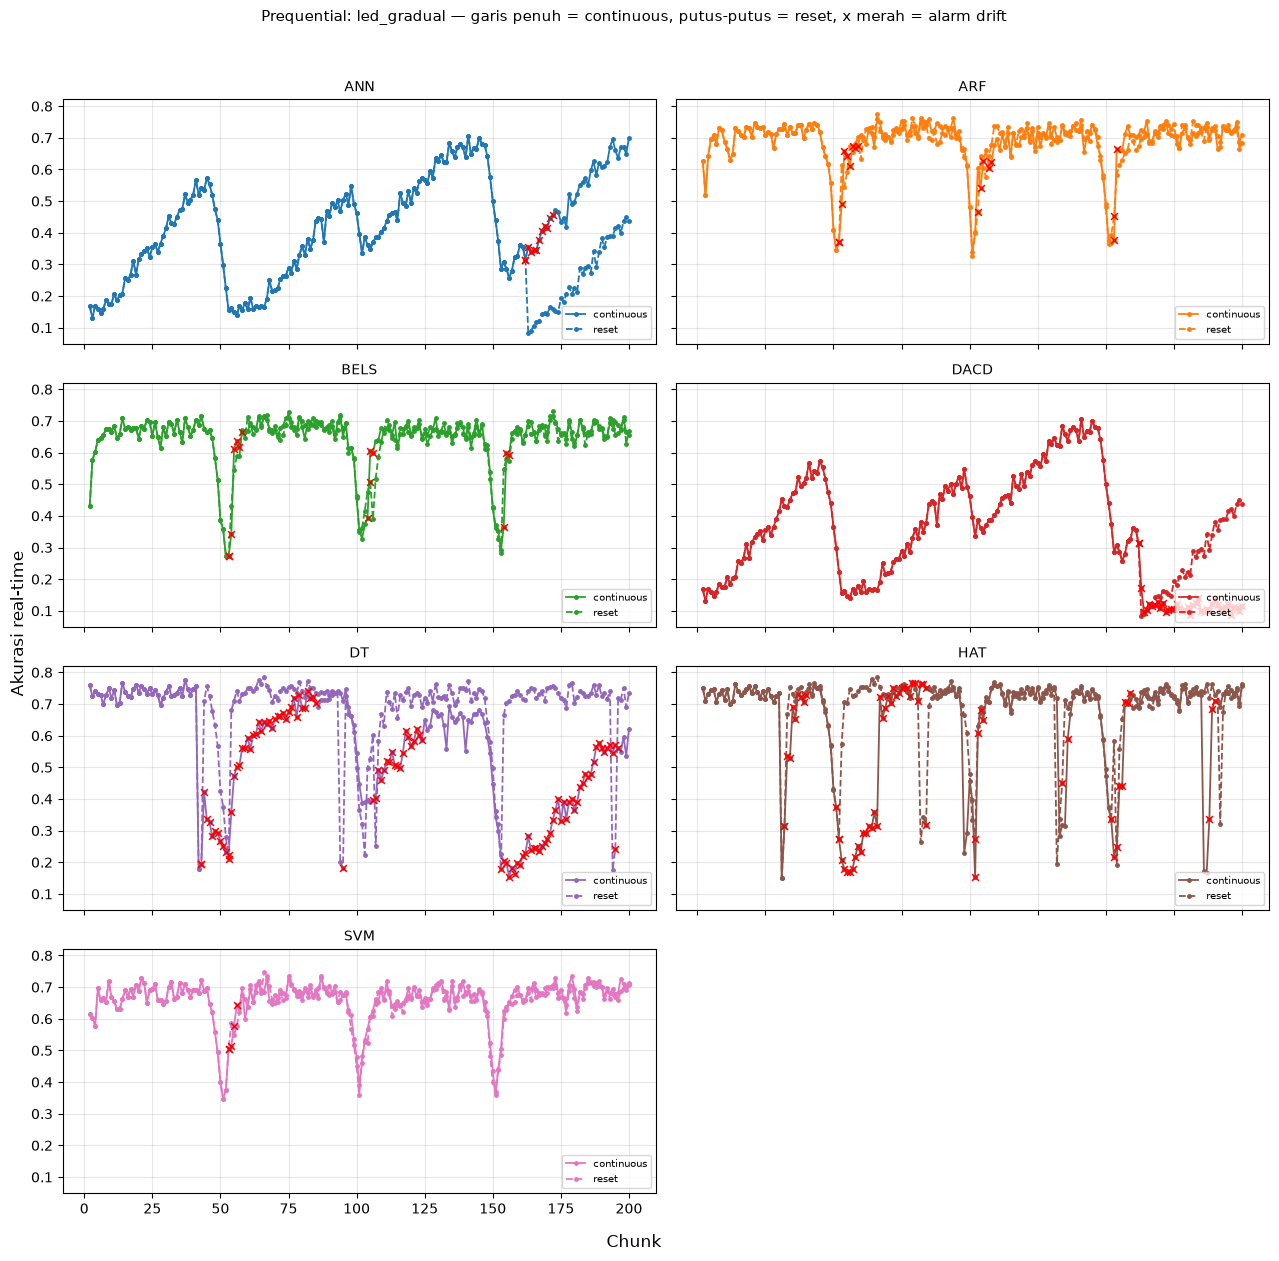

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.556804     0.507562  0.734667   0.697933     105   
      reset          200  0.681960     0.646622  0.734667   0.697933       5   
HAT   continuous     200  0.642221     0.602469  0.735143   0.698386      58   
      reset          200  0.685719     0.650801  0.735143   0.698386       6   
ARF   continuous     200  0.685899     0.651001  0.689238   0.654776      14   
      reset          200  0.684241     0.649161  0.689238   0.654776       3   
SVM   continuous     200  0.658492     0.620548  0.666571   0.633243       4   
      reset          200  0.653327     0.614807  0.666571   0.633243       1   
ANN   continuous     200  0.423126     0.359055  0.220095   0.209090      11   
      reset          200  0.372121     0.302409  0.220095   0.209090       1   
BELS  continuous     200  0.641236     0.601379  0.650095   0.617590      12   
      reset          200  0.639437     0.599379  0.650095   0.617590       2   
DACD  continuous     200  0.343799     0.270969  0.220095   0.209090      39   
      reset          200  0.372121     0.302409  0.220095   0.209090       1   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.030151  0.723618         34      428.442770  
      reset       0.065327  0.211055          1      471.095176  
HAT   continuous  0.065327  0.306533          5      689.269394  
      reset       0.060302  0.226131          2      675.429135  
ARF   continuous  0.040201  0.150754          2     2366.610979  
      reset       0.040201  0.185930          4     2331.656366  
SVM   continuous  0.035176  0.170854          3       33.680138  
      reset       0.050251  0.201005          5       33.866239  
ANN   continuous  0.010050  0.140704          1       48.140960  
      reset       0.020101  0.221106         16       48.430789  
BELS  continuous  0.035176  0.160804          3       27.359176  
      reset       0.025126  0.180905          5       24.517173  
DACD  continuous  0.015075  0.331658         -1       92.302489  
      reset       0.020101  0.221106         16       89.841622

In [ ]:
run_dataset("led_gradual")

## Tree — abrupt drift 25/50/75% (chunk 51, 101, 151)

=== tree | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    2.5s remaining:   15.3s


  >> DT    continuous avg_acc=0.4571 kappa=0.3559 alarm=129 RT=37 PDE=0.050 FTDE=0.724 lat=565.3ms
  >> DT    reset      avg_acc=0.7385 kappa=0.6922 alarm=3 RT=2 PDE=0.055 FTDE=0.146 lat=449.8ms
  >> HAT   continuous avg_acc=0.7602 kappa=0.7174 alarm=81 RT=1 PDE=0.045 FTDE=0.126 lat=716.8ms
  >> HAT   reset      avg_acc=0.7427 kappa=0.6973 alarm=3 RT=2 PDE=0.050 FTDE=0.141 lat=728.4ms
  >> ARF   continuous avg_acc=0.6659 kappa=0.6027 alarm=38 RT=3 PDE=0.156 FTDE=0.432 lat=2005.1ms
  >> ARF   reset      avg_acc=0.6504 kappa=0.5834 alarm=1 RT=14 PDE=0.090 FTDE=0.548 lat=2011.9ms
  >> SVM   continuous avg_acc=0.5528 kappa=0.4756 alarm=0 RT=-1 PDE=0.126 FTDE=0.337 lat=30.2ms
  >> SVM   reset      avg_acc=0.5528 kappa=0.4756 alarm=0 RT=-1 PDE=0.126 FTDE=0.337 lat=30.2ms
  >> ANN   continuous avg_acc=0.3039 kappa=0.1753 alarm=0 RT=-1 PDE=0.030 FTDE=0.452 lat=43.2ms
  >> ANN   reset      avg_acc=0.3039 kappa=0.1753 alarm=0 RT=-1 PDE=0.030 FTDE=0.452 lat=43.0ms
  >> BELS  continuous avg_acc=0.

[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    2.8s finished


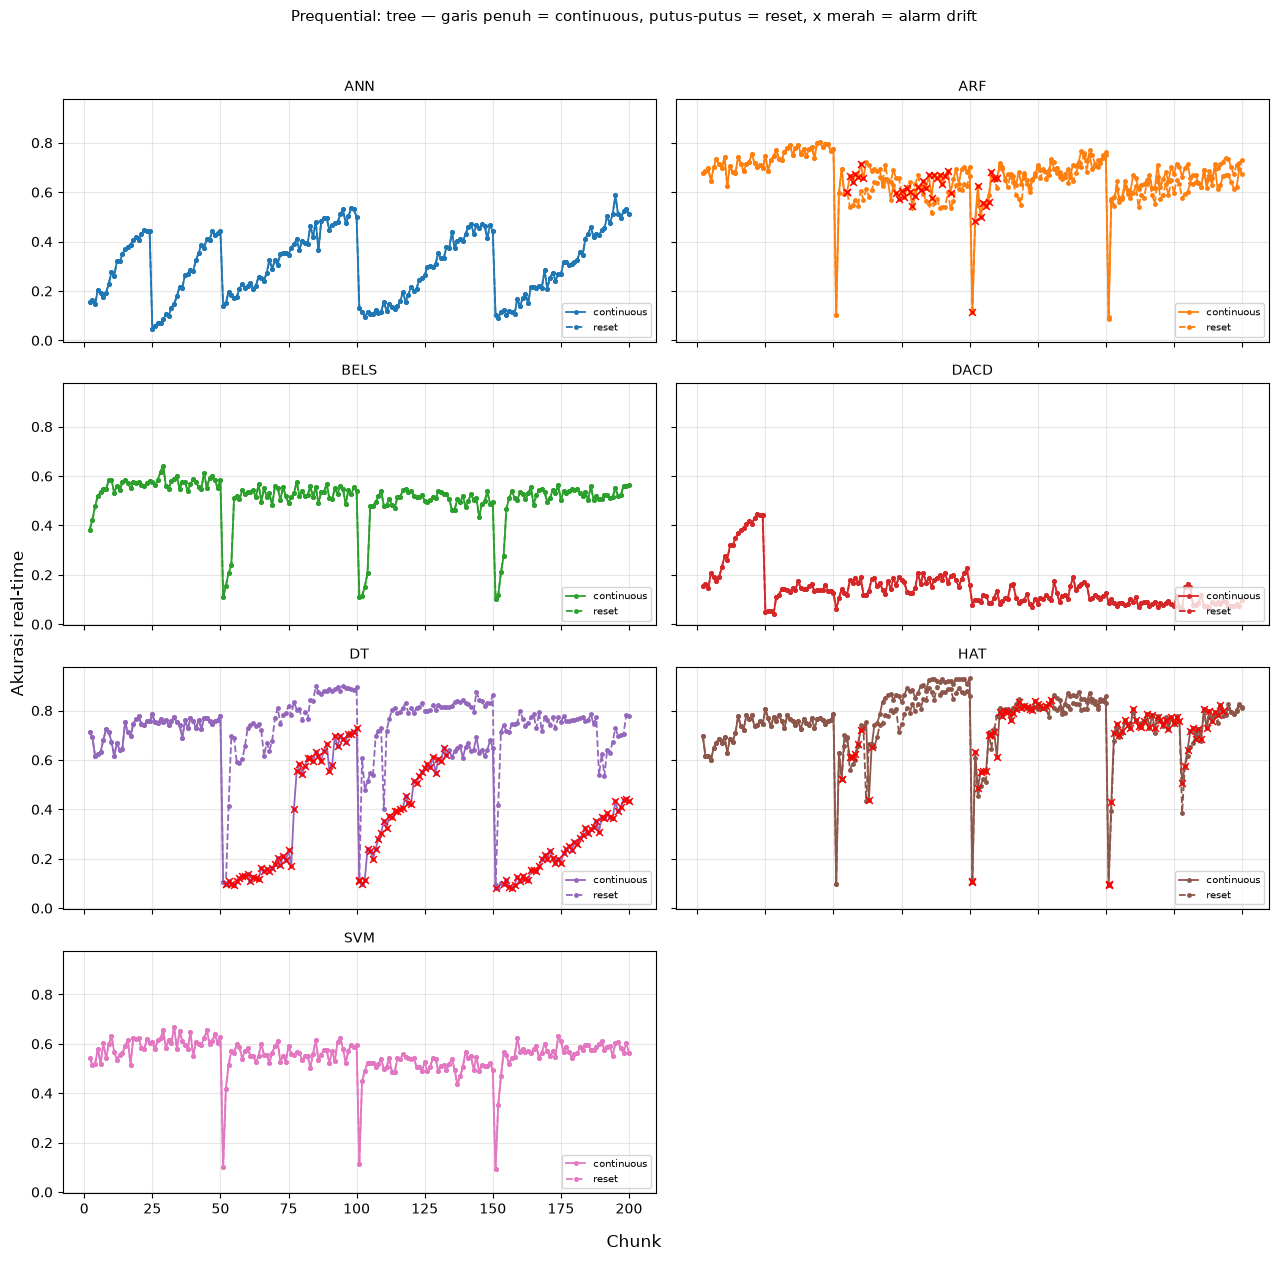

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.457095     0.355863  0.693714   0.659029     129   
      reset          200  0.738513     0.692173  0.693714   0.659029       3   
HAT   continuous     200  0.760171     0.717444  0.696952   0.662105      81   
      reset          200  0.742714     0.697321  0.696952   0.662105       3   
ARF   continuous     200  0.665889     0.602690  0.701429   0.666357      38   
      reset          200  0.650352     0.583412  0.701429   0.666357       1   
SVM   continuous     200  0.552804     0.475566  0.572381   0.543762       0   
      reset          200  0.552804     0.475566  0.572381   0.543762       0   
ANN   continuous     200  0.303879     0.175253  0.296667   0.281833       0   
      reset          200  0.303879     0.175253  0.296667   0.281833       0   
BELS  continuous     200  0.509618     0.424952  0.541238   0.514176       0   
      reset          200  0.509618     0.424952  0.541238   0.514176       0   
DACD  continuous     200  0.144965     0.044049  0.296667   0.281833       0   
      reset          200  0.144965     0.044049  0.296667   0.281833       0   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.050251  0.723618         37      565.298342  
      reset       0.055276  0.145729          2      449.795437  
HAT   continuous  0.045226  0.125628          1      716.811086  
      reset       0.050251  0.140704          2      728.357698  
ARF   continuous  0.155779  0.432161          3     2005.144421  
      reset       0.090452  0.547739         14     2011.901526  
SVM   continuous  0.125628  0.336683         -1       30.153804  
      reset       0.125628  0.336683         -1       30.245786  
ANN   continuous  0.030151  0.452261         -1       43.208481  
      reset       0.030151  0.452261         -1       43.037822  
BELS  continuous  0.140704  0.351759         -1       23.265943  
      reset       0.140704  0.351759         -1       23.470901  
DACD  continuous  0.010050  0.934673         -1       91.398637  
      reset       0.010050  0.934673         -1       92.142937

In [ ]:
run_dataset("tree")

## Hyperplane — incremental drift (bergesar tiap sampel, tanpa titik tunggal)

=== hyperplane | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    0.7s remaining:    4.4s


  >> DT    continuous avg_acc=0.8674 kappa=0.7349 alarm=0 RT=-1 PDE=0.040 FTDE=0.045 lat=131.3ms
  >> DT    reset      avg_acc=0.8674 kappa=0.7349 alarm=0 RT=-1 PDE=0.040 FTDE=0.045 lat=130.0ms
  >> HAT   continuous avg_acc=0.8624 kappa=0.7248 alarm=0 RT=-1 PDE=0.005 FTDE=0.005 lat=329.0ms
  >> HAT   reset      avg_acc=0.8624 kappa=0.7248 alarm=0 RT=-1 PDE=0.005 FTDE=0.005 lat=320.1ms
  >> ARF   continuous avg_acc=0.8440 kappa=0.6880 alarm=0 RT=-1 PDE=0.005 FTDE=0.005 lat=1689.8ms
  >> ARF   reset      avg_acc=0.8440 kappa=0.6880 alarm=0 RT=-1 PDE=0.005 FTDE=0.005 lat=1695.7ms
  >> SVM   continuous avg_acc=0.8653 kappa=0.7307 alarm=0 RT=-1 PDE=0.015 FTDE=0.020 lat=22.2ms
  >> SVM   reset      avg_acc=0.8653 kappa=0.7307 alarm=0 RT=-1 PDE=0.015 FTDE=0.020 lat=22.9ms
  >> ANN   continuous avg_acc=0.8431 kappa=0.6862 alarm=0 RT=-1 PDE=0.010 FTDE=0.050 lat=32.8ms
  >> ANN   reset      avg_acc=0.8431 kappa=0.6862 alarm=0 RT=-1 PDE=0.010 FTDE=0.050 lat=33.1ms
  >> BELS  continuous avg_acc=0.

[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    1.1s finished


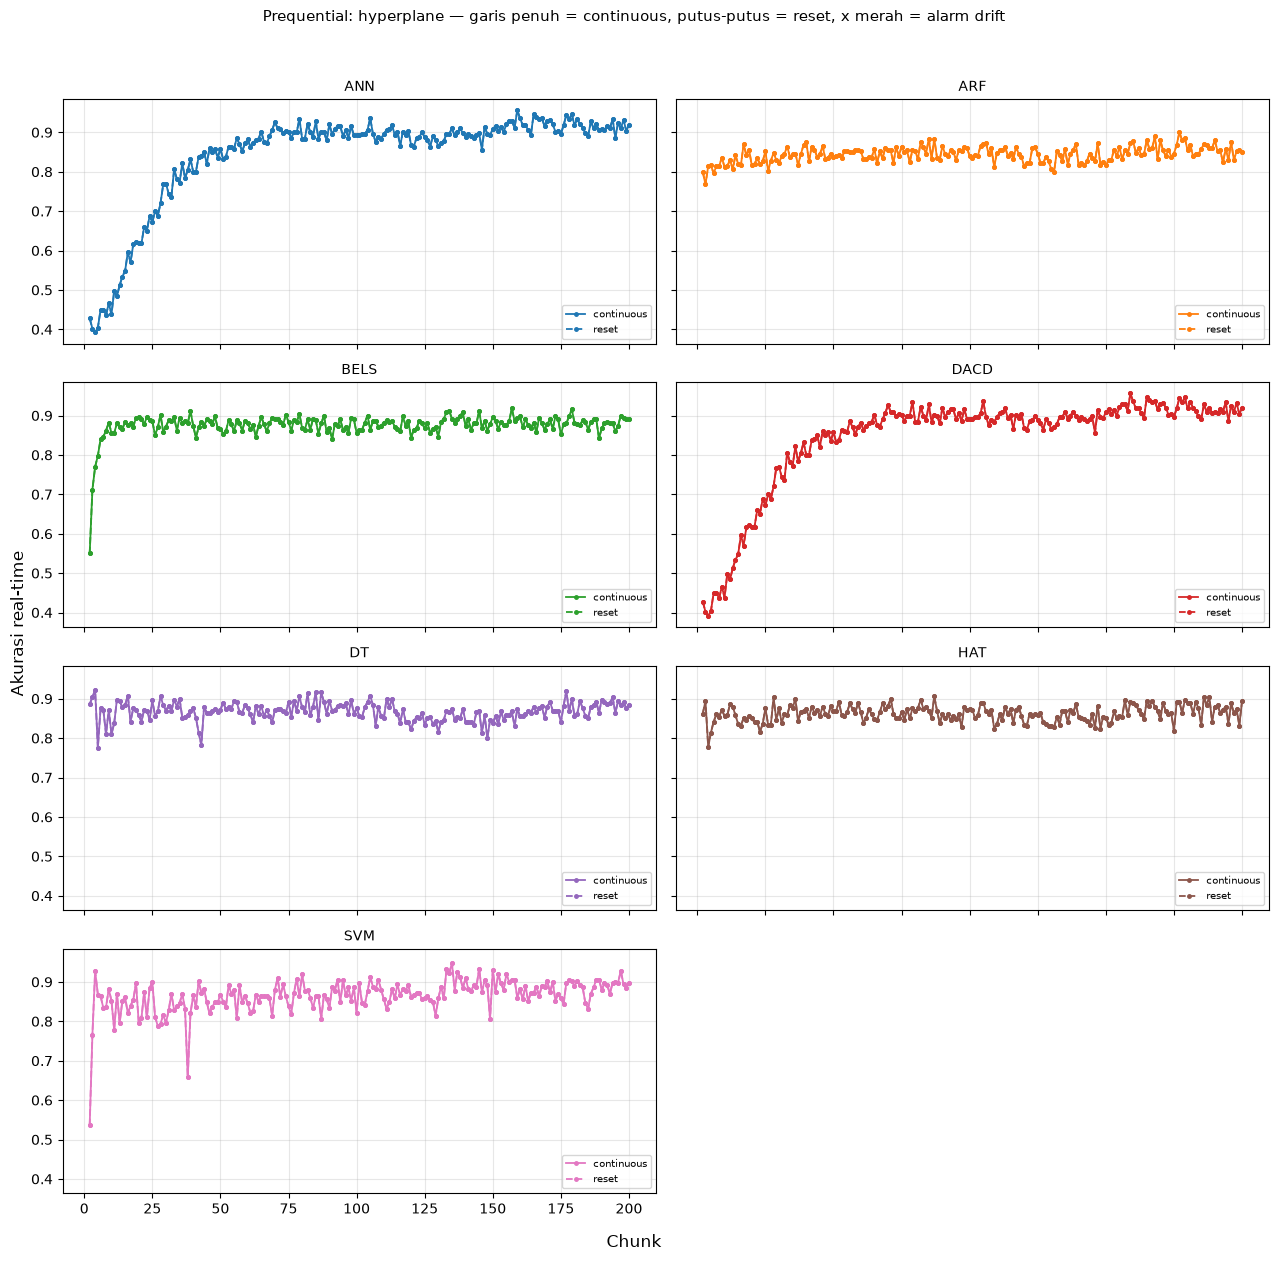

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     200  0.867447     0.734894  0.866190   0.822881       0   
      reset          200  0.867447     0.734894  0.866190   0.822881       0   
HAT   continuous     200  0.862392     0.724782  0.850762   0.808224       0   
      reset          200  0.862392     0.724782  0.850762   0.808224       0   
ARF   continuous     200  0.843990     0.687979  0.820762   0.779724       0   
      reset          200  0.843990     0.687979  0.820762   0.779724       0   
SVM   continuous     200  0.865347     0.730692  0.829238   0.787776       0   
      reset          200  0.865347     0.730692  0.829238   0.787776       0   
ANN   continuous     200  0.843075     0.686151  0.511524   0.485948       0   
      reset          200  0.843075     0.686151  0.511524   0.485948       0   
BELS  continuous     200  0.875226     0.750459  0.840857   0.798814       0   
      reset          200  0.875226     0.750459  0.840857   0.798814       0   
DACD  continuous     200  0.843075     0.686151  0.511524   0.485948       0   
      reset          200  0.843075     0.686151  0.511524   0.485948       0   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.040201  0.045226         -1      131.308414  
      reset       0.040201  0.045226         -1      129.950756  
HAT   continuous  0.005025  0.005025         -1      328.962554  
      reset       0.005025  0.005025         -1      320.129254  
ARF   continuous  0.005025  0.005025         -1     1689.845552  
      reset       0.005025  0.005025         -1     1695.690833  
SVM   continuous  0.015075  0.020101         -1       22.238191  
      reset       0.015075  0.020101         -1       22.904433  
ANN   continuous  0.010050  0.050251         -1       32.844267  
      reset       0.010050  0.050251         -1       33.088012  
BELS  continuous  0.005025  0.020101         -1       27.208008  
      reset       0.005025  0.020101         -1       27.688761  
DACD  continuous  0.010050  0.050251         -1       81.240704  
      reset       0.010050  0.050251         -1       82.179727

In [ ]:
run_dataset("hyperplane")

## Electricity (Elec2) — real-world, 45.312 baris; posisi drift tidak diketahui (drift alami)

=== electricity | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.


  >> DT    continuous avg_acc=0.7496 kappa=0.4810 alarm=31 RT=1 PDE=0.167 FTDE=0.500 lat=105.0ms
  >> DT    reset      avg_acc=0.7694 kappa=0.5203 alarm=2 RT=1 PDE=0.178 FTDE=0.389 lat=101.9ms
  >> HAT   continuous avg_acc=0.7554 kappa=0.4914 alarm=28 RT=4 PDE=0.200 FTDE=0.444 lat=209.2ms
  >> HAT   reset      avg_acc=0.7592 kappa=0.5002 alarm=1 RT=1 PDE=0.211 FTDE=0.411 lat=193.7ms
  >> ARF   continuous avg_acc=0.7796 kappa=0.5443 alarm=1 RT=1 PDE=0.189 FTDE=0.344 lat=1038.2ms
  >> ARF   reset      avg_acc=0.7752 kappa=0.5345 alarm=2 RT=1 PDE=0.200 FTDE=0.356 lat=997.2ms
  >> SVM   continuous avg_acc=0.7123 kappa=0.4094 alarm=28 RT=3 PDE=0.200 FTDE=0.400 lat=24.8ms
  >> SVM   reset      avg_acc=0.7182 kappa=0.4236 alarm=1 RT=2 PDE=0.178 FTDE=0.422 lat=24.7ms
  >> ANN   continuous avg_acc=0.6764 kappa=0.3460 alarm=0 RT=-1 PDE=0.033 FTDE=0.044 lat=35.6ms
  >> ANN   reset      avg_acc=0.6764 kappa=0.3460 alarm=0 RT=-1 PDE=0.033 FTDE=0.044 lat=34.7ms


[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    0.2s remaining:    1.8s
[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    0.4s finished


  >> BELS  continuous avg_acc=0.7589 kappa=0.4945 alarm=48 RT=4 PDE=0.167 FTDE=0.489 lat=27.1ms
  >> BELS  reset      avg_acc=0.7729 kappa=0.5233 alarm=2 RT=1 PDE=0.167 FTDE=0.478 lat=27.1ms
  >> DACD  continuous avg_acc=0.6764 kappa=0.3460 alarm=0 RT=-1 PDE=0.033 FTDE=0.044 lat=91.9ms
  >> DACD  reset      avg_acc=0.6764 kappa=0.3460 alarm=0 RT=-1 PDE=0.033 FTDE=0.044 lat=90.8ms


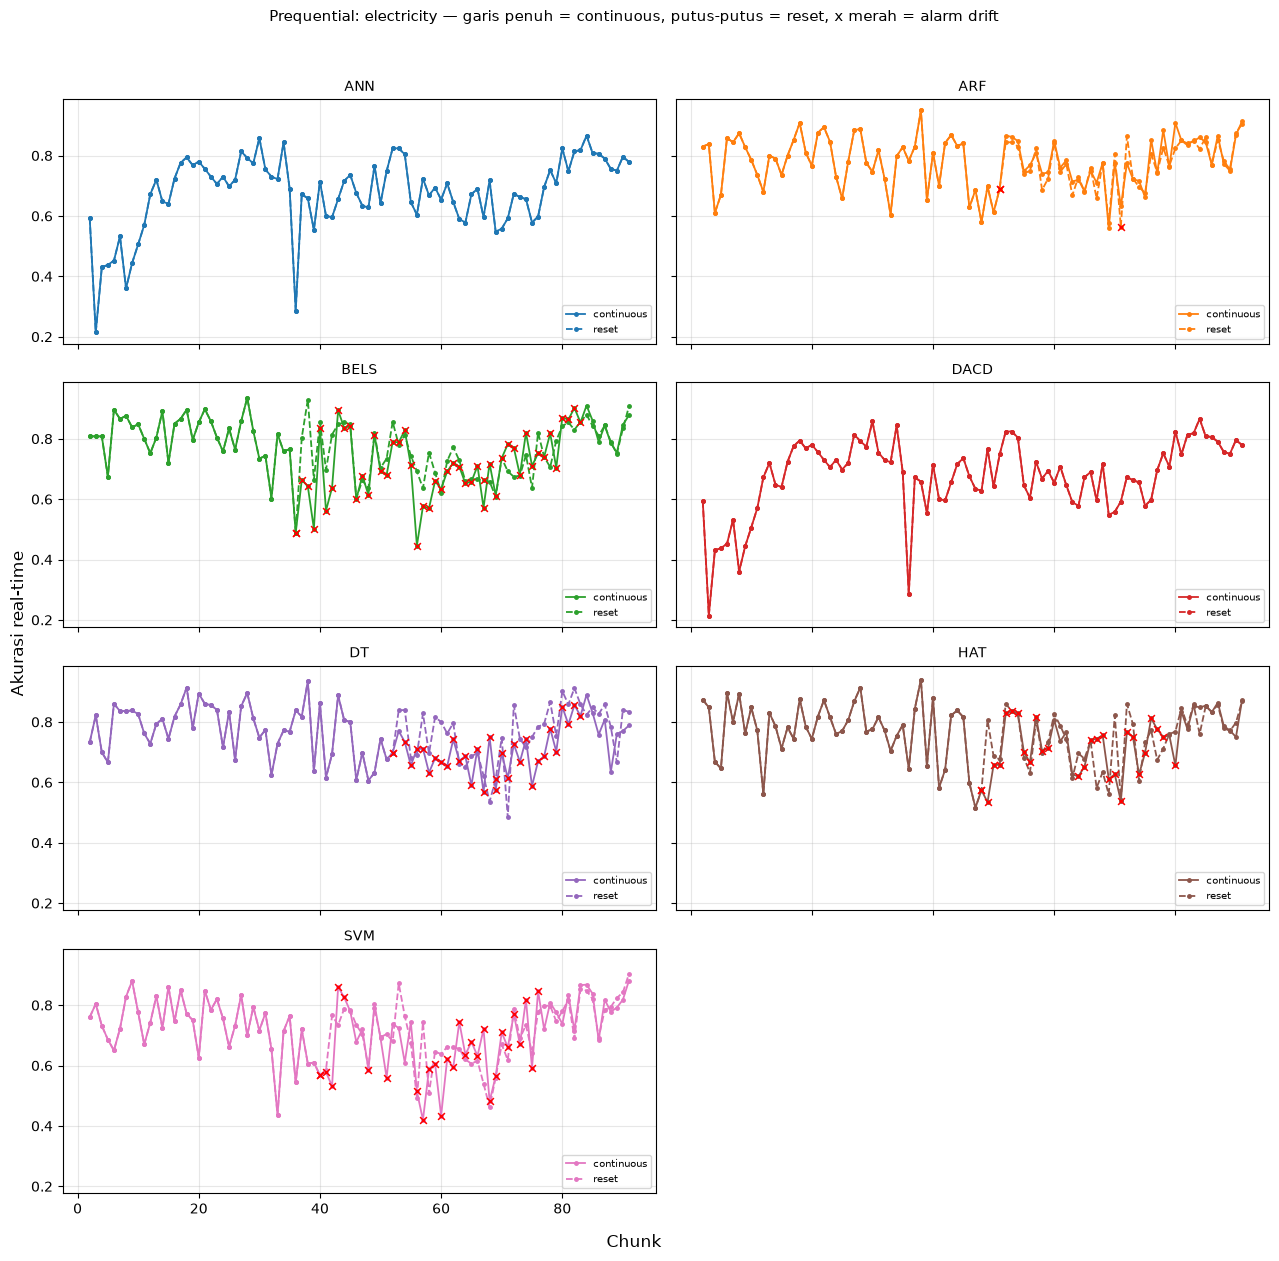

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous      91  0.749627     0.481039    0.7878    0.74841      31   
      reset           91  0.769437     0.520292    0.7878    0.74841       2   
HAT   continuous      91  0.755375     0.491355    0.8008    0.76076      28   
      reset           91  0.759184     0.500184    0.8008    0.76076       1   
ARF   continuous      91  0.779616     0.544307    0.7874    0.74803       1   
      reset           91  0.775176     0.534479    0.7874    0.74803       2   
SVM   continuous      91  0.712327     0.409367    0.7508    0.71326      28   
      reset           91  0.718154     0.423556    0.7508    0.71326       1   
ANN   continuous      91  0.676432     0.346006    0.4540    0.43130       0   
      reset           91  0.676432     0.346006    0.4540    0.43130       0   
BELS  continuous      91  0.758936     0.494476    0.8222    0.78109      48   
      reset           91  0.772923     0.523312    0.8222    0.78109       2   
DACD  continuous      91  0.676432     0.346006    0.4540    0.43130       0   
      reset           91  0.676432     0.346006    0.4540    0.43130       0   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.166667  0.500000          1      104.962598  
      reset       0.177778  0.388889          1      101.908036  
HAT   continuous  0.200000  0.444444          4      209.229646  
      reset       0.211111  0.411111          1      193.740820  
ARF   continuous  0.188889  0.344444          1     1038.226182  
      reset       0.200000  0.355556          1      997.235690  
SVM   continuous  0.200000  0.400000          3       24.814176  
      reset       0.177778  0.422222          2       24.677247  
ANN   continuous  0.033333  0.044444         -1       35.588567  
      reset       0.033333  0.044444         -1       34.734692  
BELS  continuous  0.166667  0.488889          4       27.083860  
      reset       0.166667  0.477778          1       27.131325  
DACD  continuous  0.033333  0.044444         -1       91.914151  
      reset       0.033333  0.044444         -1       90.809060

In [ ]:
run_dataset("electricity")

## Weather (BASEL) — real-world, 3.654 baris, 8 chunk; drift alami bila ada

=== weather | 14 run paralel | 14 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.


  >> DT    continuous avg_acc=0.9391 kappa=0.8329 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=81.0ms
  >> DT    reset      avg_acc=0.9391 kappa=0.8329 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=80.0ms
  >> HAT   continuous avg_acc=0.9366 kappa=0.8284 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=131.4ms
  >> HAT   reset      avg_acc=0.9366 kappa=0.8284 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=123.1ms
  >> ARF   continuous avg_acc=0.9759 kappa=0.9326 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=696.2ms
  >> ARF   reset      avg_acc=0.9759 kappa=0.9326 alarm=0 RT=-1 PDE=0.000 FTDE=0.000 lat=694.3ms
  >> SVM   continuous avg_acc=0.8888 kappa=0.6991 alarm=0 RT=-1 PDE=0.143 FTDE=0.143 lat=15.5ms
  >> SVM   reset      avg_acc=0.8888 kappa=0.6991 alarm=0 RT=-1 PDE=0.143 FTDE=0.143 lat=15.1ms
  >> ANN   continuous avg_acc=0.7103 kappa=0.4307 alarm=0 RT=-1 PDE=0.143 FTDE=0.143 lat=27.7ms
  >> ANN   reset      avg_acc=0.7103 kappa=0.4307 alarm=0 RT=-1 PDE=0.143 FTDE=0.143 lat=27.3ms
  >> BELS  continuous avg_acc=0.8507

[Parallel(n_jobs=14)]: Done   2 out of  14 | elapsed:    0.2s remaining:    1.9s
[Parallel(n_jobs=14)]: Done  14 out of  14 | elapsed:    0.4s finished


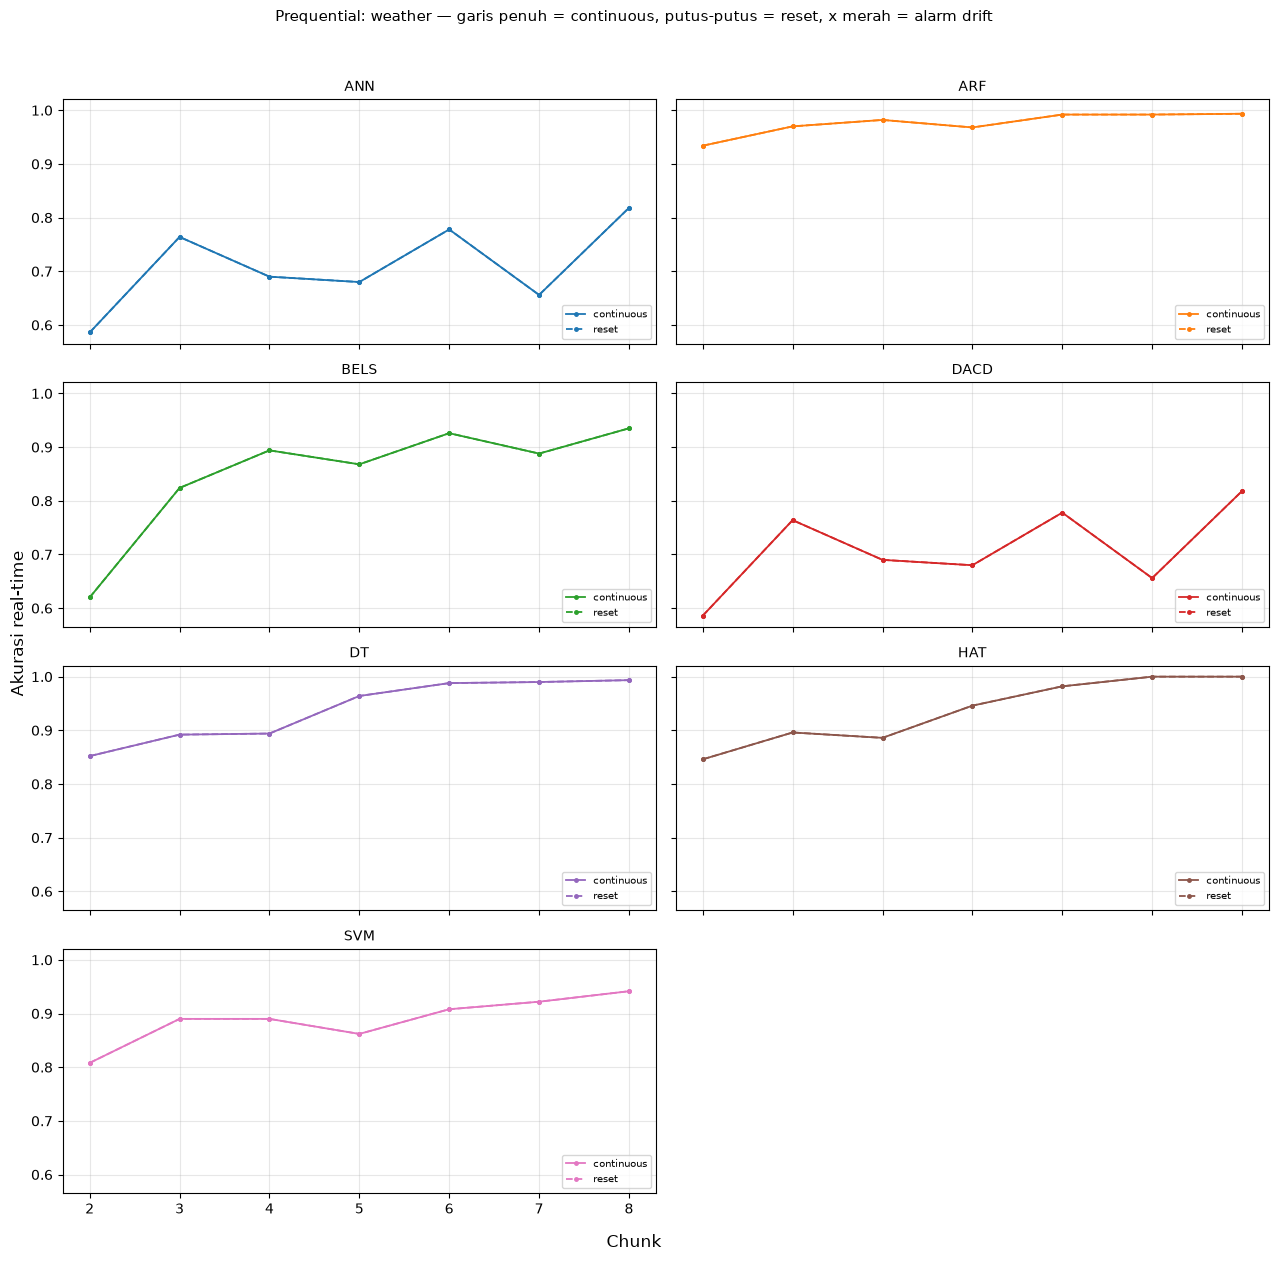

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous       8  0.939072     0.832875  0.879333   0.835367       0   
      reset            8  0.939072     0.832875  0.879333   0.835367       0   
HAT   continuous       8  0.936571     0.828354  0.876000   0.832200       0   
      reset            8  0.936571     0.828354  0.876000   0.832200       0   
ARF   continuous       8  0.975929     0.932595  0.962000   0.913900       0   
      reset            8  0.975929     0.932595  0.962000   0.913900       0   
SVM   continuous       8  0.888794     0.699139  0.862667   0.819533       0   
      reset            8  0.888794     0.699139  0.862667   0.819533       0   
ANN   continuous       8  0.710312     0.430689  0.680000   0.646000       0   
      reset            8  0.710312     0.430689  0.680000   0.646000       0   
BELS  continuous       8  0.850724     0.630484  0.779333   0.740367       0   
      reset            8  0.850724     0.630484  0.779333   0.740367       0   
DACD  continuous       8  0.710312     0.430689  0.680000   0.646000       0   
      reset            8  0.710312     0.430689  0.680000   0.646000       0   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.000000  0.000000         -1       81.047275  
      reset       0.000000  0.000000         -1       80.007600  
HAT   continuous  0.000000  0.000000         -1      131.440587  
      reset       0.000000  0.000000         -1      123.068075  
ARF   continuous  0.000000  0.000000         -1      696.173200  
      reset       0.000000  0.000000         -1      694.266175  
SVM   continuous  0.142857  0.142857         -1       15.517063  
      reset       0.142857  0.142857         -1       15.061125  
ANN   continuous  0.142857  0.142857         -1       27.705238  
      reset       0.142857  0.142857         -1       27.273275  
BELS  continuous  0.142857  0.142857         -1       18.371263  
      reset       0.142857  0.142857         -1       24.624137  
DACD  continuous  0.142857  0.142857         -1       77.405163  
      reset       0.142857  0.142857         -1       76.456462

In [ ]:
run_dataset("weather")

## KDD Cup 1999 (10%) — real-world, 494.020 baris = 988 chunk; drift alami, ±20-30 menit

=== kddcup99 | 14 run paralel | 10 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  10 out of  14 | elapsed:    8.2s remaining:    3.2s


  >> DT    continuous avg_acc=0.9685 kappa=0.9470 alarm=632 RT=8 PDE=0.037 FTDE=0.087 lat=485.3ms
  >> DT    reset      avg_acc=0.9633 kappa=0.9380 alarm=32 RT=1 PDE=0.040 FTDE=0.082 lat=547.1ms
  >> HAT   continuous avg_acc=0.6353 kappa=0.3219 alarm=642 RT=3 PDE=0.016 FTDE=0.373 lat=230.6ms
  >> HAT   reset      avg_acc=0.9624 kappa=0.9363 alarm=28 RT=1 PDE=0.037 FTDE=0.074 lat=706.9ms
  >> ARF   continuous avg_acc=0.9694 kappa=0.9481 alarm=640 RT=1 PDE=0.039 FTDE=0.067 lat=989.8ms
  >> ARF   reset      avg_acc=0.9691 kappa=0.9476 alarm=30 RT=1 PDE=0.041 FTDE=0.063 lat=960.9ms
  >> SVM   continuous avg_acc=0.3314 kappa=0.1624 alarm=463 RT=2 PDE=0.045 FTDE=0.681 lat=62.7ms
  >> SVM   reset      avg_acc=0.8167 kappa=0.7062 alarm=15 RT=2 PDE=0.028 FTDE=0.204 lat=63.2ms
  >> ANN   continuous avg_acc=0.8668 kappa=0.7835 alarm=578 RT=19 PDE=0.038 FTDE=0.224 lat=69.9ms
  >> ANN   reset      avg_acc=0.8427 kappa=0.7488 alarm=25 RT=1 PDE=0.031 FTDE=0.179 lat=58.3ms
  >> BELS  continuous avg_ac

[Parallel(n_jobs=10)]: Done  14 out of  14 | elapsed:   11.9s finished


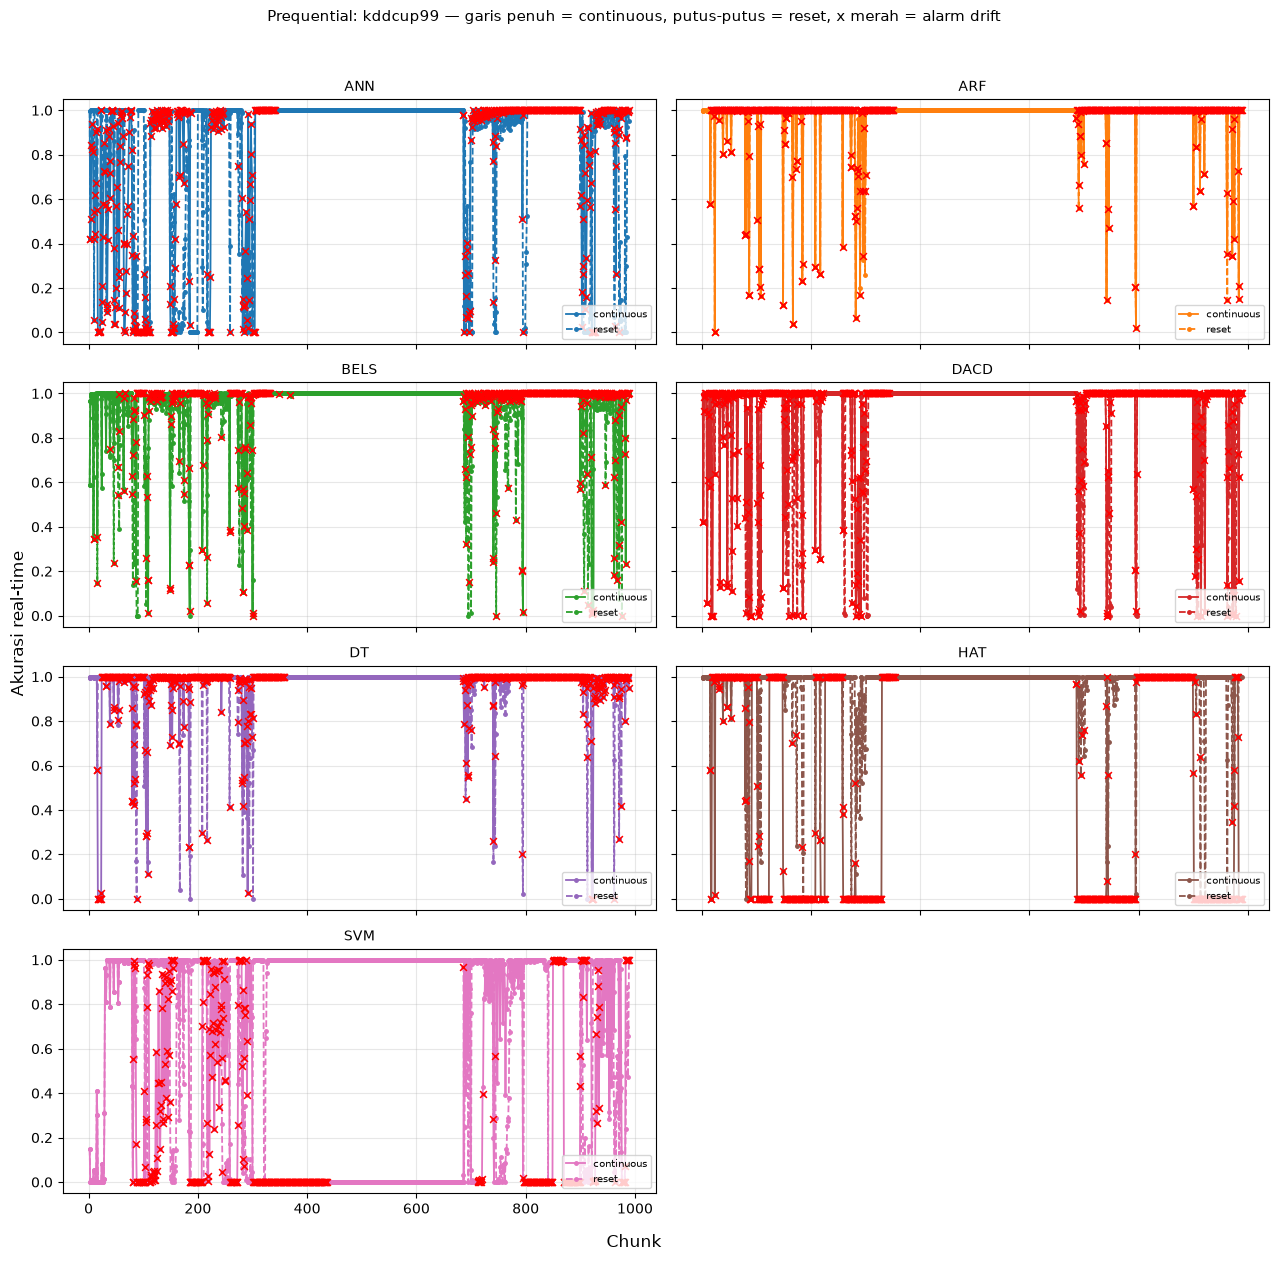

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous     989  0.968524     0.947026  0.999879   0.949885     632   
      reset          989  0.963265     0.938036  0.970889   0.922344      32   
HAT   continuous     989  0.635283     0.321941  0.999919   0.949923     642   
      reset          989  0.962379     0.936343  0.938949   0.892002      28   
ARF   continuous     989  0.969370     0.948080  0.999919   0.949923     640   
      reset          989  0.969099     0.947603  0.976505   0.927680      30   
SVM   continuous     989  0.331423     0.162406  0.704848   0.669606     463   
      reset          989  0.816727     0.706156  0.695192   0.660432      15   
ANN   continuous     989  0.866842     0.783480  0.991798   0.942208     578   
      reset          989  0.842713     0.748803  0.851273   0.808709      25   
BELS  continuous     989  0.959065     0.930882  0.969131   0.920675     506   
      reset          989  0.919684     0.866204  0.861111   0.818056      37   
DACD  continuous     989  0.937221     0.894804  0.999697   0.949712     600   
      reset          989  0.903826     0.840635  0.885131   0.840875      33   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.037449  0.087045          8      485.294658  
      reset       0.040486  0.081984          1      547.145695  
HAT   continuous  0.016194  0.373482          3      230.588545  
      reset       0.037449  0.073887          1      706.898093  
ARF   continuous  0.039474  0.066802          1      989.789736  
      reset       0.041498  0.062753          1      960.941697  
SVM   continuous  0.044534  0.681174          2       62.708289  
      reset       0.028340  0.204453          2       63.154514  
ANN   continuous  0.038462  0.223684         19       69.934130  
      reset       0.031377  0.179150          1       58.302112  
BELS  continuous  0.045547  0.085020          1       53.245741  
      reset       0.047571  0.131579          2       51.878268  
DACD  continuous  0.045547  0.123482          1      244.667060  
      reset       0.049595  0.133603          1      231.495704

In [ ]:
run_dataset("kddcup99")

## Covertype — real-world, 581.012 baris = 1.163 chunk; drift alami, sel paling lama

=== covertype | 14 run paralel | 10 worker (CPU 16 thread, 2 disisakan) ===


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  10 out of  14 | elapsed:    8.7s remaining:    3.4s


  >> DT    continuous avg_acc=0.7770 kappa=0.6379 alarm=300 RT=1 PDE=0.046 FTDE=0.151 lat=278.5ms
  >> DT    reset      avg_acc=0.7946 kappa=0.6649 alarm=10 RT=1 PDE=0.052 FTDE=0.119 lat=331.9ms
  >> HAT   continuous avg_acc=0.7410 kappa=0.5782 alarm=384 RT=1 PDE=0.083 FTDE=0.305 lat=849.4ms
  >> HAT   reset      avg_acc=0.7371 kappa=0.5697 alarm=19 RT=1 PDE=0.100 FTDE=0.350 lat=811.0ms
  >> ARF   continuous avg_acc=0.7378 kappa=0.5644 alarm=363 RT=2 PDE=0.067 FTDE=0.372 lat=1590.5ms
  >> ARF   reset      avg_acc=0.7349 kappa=0.5599 alarm=12 RT=1 PDE=0.065 FTDE=0.363 lat=1589.4ms
  >> SVM   continuous avg_acc=0.6059 kappa=0.3388 alarm=190 RT=1 PDE=0.016 FTDE=0.075 lat=28.1ms
  >> SVM   reset      avg_acc=0.6155 kappa=0.3940 alarm=6 RT=1 PDE=0.019 FTDE=0.101 lat=28.4ms
  >> ANN   continuous avg_acc=0.7648 kappa=0.6167 alarm=349 RT=1 PDE=0.039 FTDE=0.120 lat=49.1ms
  >> ANN   reset      avg_acc=0.7192 kappa=0.5454 alarm=12 RT=3 PDE=0.045 FTDE=0.214 lat=46.2ms
  >> BELS  continuous avg_ac

[Parallel(n_jobs=10)]: Done  14 out of  14 | elapsed:   13.9s finished


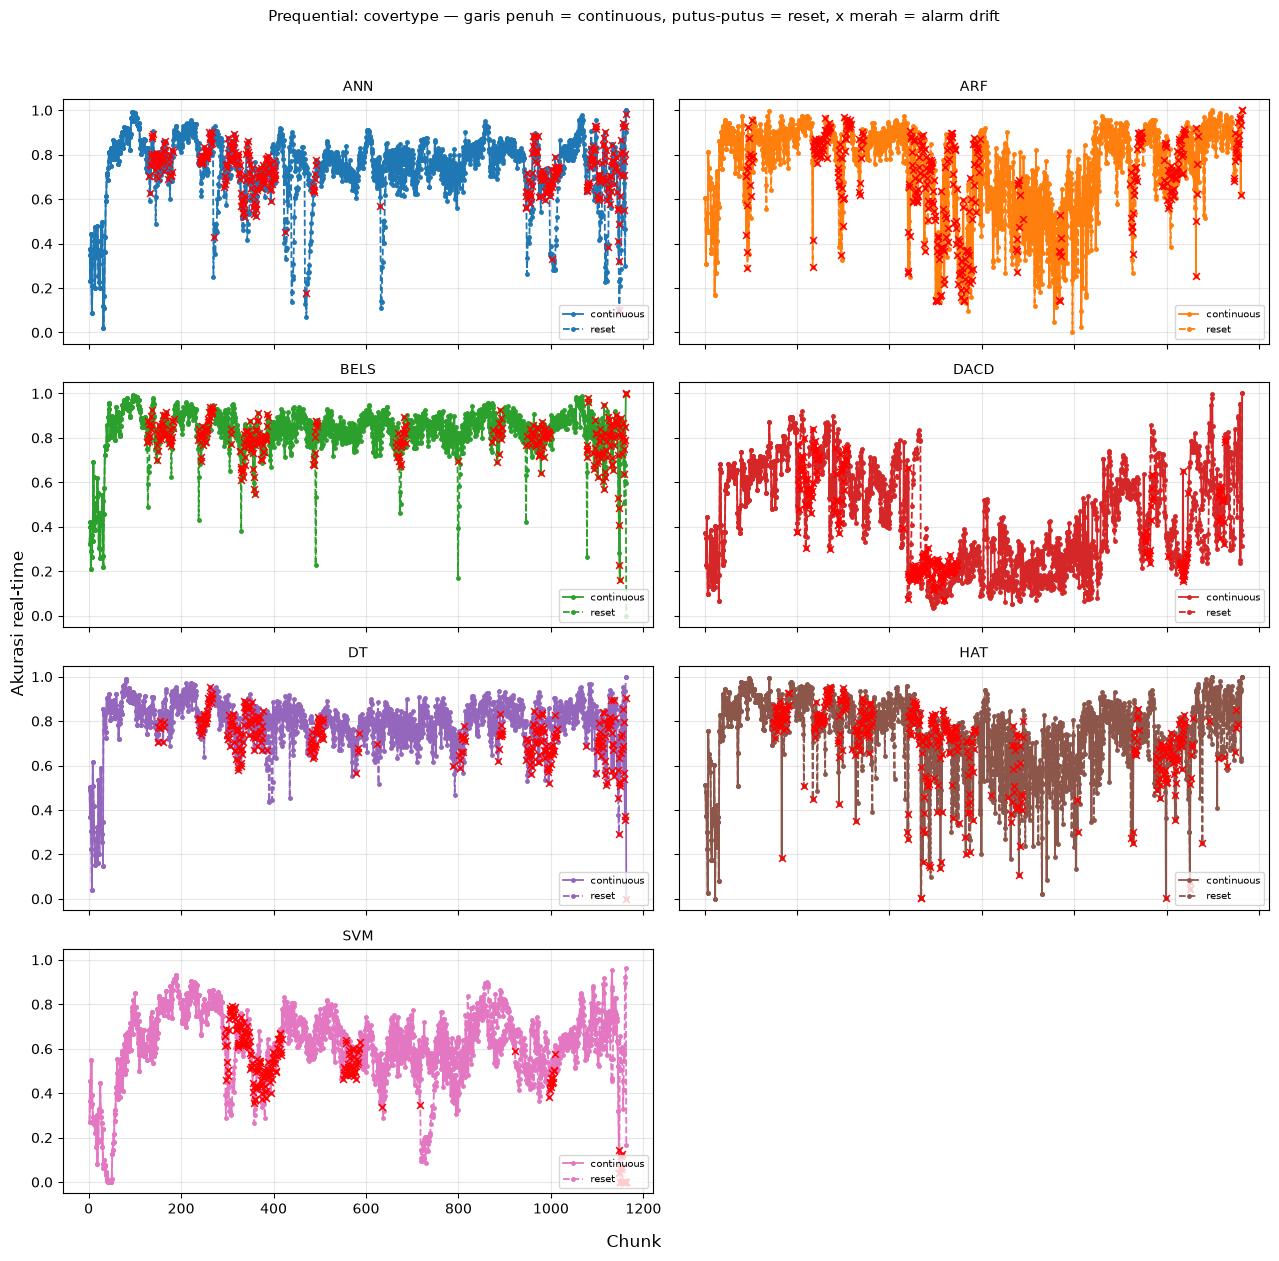

chunks   avg_acc  final_kappa  baseline  threshold  alarms  \
model strategy                                                                 
DT    continuous    1163  0.777002     0.637887  0.729043   0.692591     300   
      reset         1163  0.794551     0.664916  0.729043   0.692591      10   
HAT   continuous    1163  0.740957     0.578216  0.747197   0.709837     384   
      reset         1163  0.737107     0.569719  0.747197   0.709837      19   
ARF   continuous    1163  0.737775     0.564433  0.766701   0.728366     363   
      reset         1163  0.734904     0.559907  0.756256   0.718444      12   
SVM   continuous    1163  0.605917     0.338830  0.404650   0.384417     190   
      reset         1163  0.615469     0.393993  0.404650   0.384417       6   
ANN   continuous    1163  0.764842     0.616652  0.695880   0.661086     349   
      reset         1163  0.719220     0.545410  0.695880   0.661086      12   
BELS  continuous    1163  0.828188     0.720931  0.766564   0.728236     302   
      reset         1163  0.829394     0.725970  0.766564   0.728236       9   
DACD  continuous    1163  0.466153     0.217376  0.494444   0.469722     241   
      reset         1163  0.419602     0.162818  0.494444   0.469722       7   

                       pde      ftde  rt_chunks  avg_latency_ms  
model strategy                                                   
DT    continuous  0.045611  0.150602          1      278.484414  
      reset       0.052496  0.118761          1      331.921653  
HAT   continuous  0.082616  0.304647          1      849.366678  
      reset       0.099828  0.350258          1      811.046595  
ARF   continuous  0.067126  0.371773          2     1590.489840  
      reset       0.065404  0.363167          1     1589.352974  
SVM   continuous  0.016351  0.074871          1       28.101719  
      reset       0.018933  0.100688          1       28.360465  
ANN   continuous  0.038726  0.120482          1       49.142702  
      reset       0.044750  0.214286          3       46.210900  
BELS  continuous  0.032702  0.091222          1       23.298625  
      reset       0.023236  0.086059          5       22.967926  
DACD  continuous  0.032702  0.488812          1      144.507262  
      reset       0.038726  0.567986          2      137.550902

In [ ]:
run_dataset("covertype")

## Ringkasan semua run

In [ ]:
ringkasan = pd.DataFrame(ALL_SUMMARIES)
ringkasan.to_csv(OUT / "ringkasan_semua.csv", index=False)
ringkasan.set_index(["dataset", "model", "strategy"])[
    ["avg_acc", "final_kappa", "alarms", "rt_chunks", "pde", "ftde", "avg_latency_ms"]
].round(4)

avg_acc  final_kappa  alarms  rt_chunks     pde  \
dataset   model strategy                                                      
sea       DT    continuous   0.8439       0.6642      25          4  0.0754   
                reset        0.8614       0.7026       2          1  0.0503   
          HAT   continuous   0.8653       0.7095      11          1  0.0402   
                reset        0.8665       0.7126       1          1  0.0402   
          ARF   continuous   0.8807       0.7438       0         -1  0.0151   
...                             ...          ...     ...        ...     ...   
covertype ANN   reset        0.7192       0.5454      12          3  0.0448   
          BELS  continuous   0.8282       0.7209     302          1  0.0327   
                reset        0.8294       0.7260       9          5  0.0232   
          DACD  continuous   0.4662       0.2174     241          1  0.0327   
                reset        0.4196       0.1628       7          2  0.0387   

                              ftde  avg_latency_ms  
dataset   model strategy                            
sea       DT    continuous  0.2915         54.3488  
                reset       0.1256         53.2158  
          HAT   continuous  0.0704        124.4500  
                reset       0.0704        122.5394  
          ARF   continuous  0.0452        901.2549  
...                            ...             ...  
covertype ANN   reset       0.2143         46.2109  
          BELS  continuous  0.0912         23.2986  
                reset       0.0861         22.9679  
          DACD  continuous  0.4888        144.5073  
                reset       0.5680        137.5509  

[140 rows x 7 columns]

## Catatan

- Dataset simulasi adalah file CSV hasil generate MOA asli oleh kelompok (folder `Dataset Real Word/datasets_synthetic`), sehingga mekanisme drift (gradual/abrupt/incremental dan posisinya) persis mengikuti pengaturan MOA saat generate, bukan rekonstruksi.
- Nama folder `Dataset Real Word` agak menyesatkan: isinya dataset **simulasi** MOA; dataset **real-world** ada di folder `dataset/`. Pertimbangkan rename folder bila ingin lebih rapi (lalu sesuaikan `SIM_DIR` di sel konfigurasi).
- BELS dan DACD di sini implementasi ringkas dari ide inti paper (BELS: ensemble lapisan output mini-chunk; DACD: CUSUM + pemilihan sampel + retrain NN), bukan kode resmi penulis.
- `rt_chunks = -1` berarti tidak ada alarm drift sehingga recovery time tidak terdefinisi.
- Dataset Weather di slide tertulis 95.100 sampel dan 3 kelas; dataset Zenodo aslinya 3.654 baris dan label biner. Angka slide perlu dikoreksi.
- Covertype dan KDD adalah data statis yang dibaca berurutan sebagai stream (praktik umum, dengan limitasi urutan waktu tidak asli).